# 03 — Baselines, native measurements and error diagnostics

This notebook trains simple probabilistic baselines on the MacBook and controls native Raspberry Pi experiments over SSH. Native timers exclude SSH transport, file transfer and MacBook analysis. Secret key material never leaves the Pi process. Real key generation, encapsulation, decapsulation and reconstructed-key caching are measured; the workloads remain controlled experimental schedules.

Selection metric is mean per-session Brier loss on the three purged inner validation folds. Logistic regularization candidates are C = 0.1, 1 and 10; other predictors have fixed formulas. No final-test files are read. Predictive selection uses only training-fold outcomes. Independent development sessions diagnose generalization and support later controller selection.

In [1]:
from pathlib import Path
import hashlib, json, os, re, platform
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML
# Resolve the repository root from either the root directory or notebooks/.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks").is_dir() and (p / "dataset").is_dir()), None)
assert ROOT is not None, "run this notebook from inside the repository"
def relocate(rel):
    """Map a path recorded at acquisition time (original project layout) onto this repository's layout."""
    rel = str(rel)
    for old, new in (("Dataset/Raw/PiExperiments/", "dataset/raw/"), ("Dataset/Raw/", "dataset/raw/"), ("Raw/", "raw/"),
                     ("Dataset/Interim/", "dataset/interim/"), ("Dataset/Processed/", "dataset/processed/"),
                     ("Dataset/Splits/", "dataset/splits/"), ("Dataset/Provenance/", "dataset/provenance/"),
                     ("Artifacts/Models/", "support/models/"), ("Artifacts/Binaries/", "support/binaries/"),
                     ("Configs/", "support/configs/"), ("Manifests/", "support/manifests/"), ("Native/", "support/native/"),
                     ("Reports/CoreCalibration/", "support/calibration/"), ("Tables/", "artifacts/"), ("Figures/", "figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
def acquisition_path(path):
    """Inverse of relocate: a repository path written in the acquisition-time layout used inside frozen records."""
    path = Path(path)
    rel = str(path.resolve().relative_to(ROOT)) if path.is_absolute() else str(path)
    for old, new in (("dataset/raw/MLKEM_TestVectors/", "Dataset/Raw/MLKEM_TestVectors/"), ("dataset/raw/IoT23/", "Dataset/Raw/IoT23/"),
                     ("dataset/raw/", "Dataset/Raw/PiExperiments/"), ("dataset/interim/", "Dataset/Interim/"),
                     ("dataset/processed/", "Dataset/Processed/"), ("dataset/splits/", "Dataset/Splits/"),
                     ("dataset/provenance/", "Dataset/Provenance/"), ("support/models/", "Artifacts/Models/"),
                     ("support/binaries/", "Artifacts/Binaries/"), ("support/configs/", "Configs/"), ("support/manifests/", "Manifests/"),
                     ("support/native/", "Native/"), ("support/calibration/", "Reports/CoreCalibration/"),
                     ("artifacts/", "Tables/"), ("figures/", "Figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
from datetime import datetime, timezone
REPLAY_DIR = ROOT/"artifacts/replays/03"/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
for subdir in ["Tables","Figures","Interim","Configs","Artifacts/Models"]:
    (REPLAY_DIR/subdir).mkdir(parents=True,exist_ok=False)
DATA = ROOT / "dataset"
RAW = DATA / "raw"
TABLES, FIGURES = REPLAY_DIR/"Tables", REPLAY_DIR/"Figures"
for p in (TABLES, FIGURES, DATA / "interim", DATA / "splits"):
    p.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 180)
try:
    font_manager.findfont("Times New Roman", fallback_to_default=False); FONT_FAMILY = "Times New Roman"
except ValueError:
    FONT_FAMILY = "serif"  # the published figures use Times New Roman; any serif font keeps the layout
mpl.rcParams.update({"font.family": FONT_FAMILY, "font.size":18,
    "axes.titlesize":20,"axes.labelsize":20,"xtick.labelsize":18,
    "ytick.labelsize":18,"legend.fontsize":18,"figure.dpi":350,
    "savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#4D4D4D"]

def save_table(frame, name, *, show=True, exclude=(), columns=None):
    frame.to_csv(TABLES / f"03_{name}.csv", index=True)
    frame.to_latex(TABLES / f"03_{name}.tex", index=True, escape=True, float_format=lambda v: f"{v:.3e}" if v and abs(v)<.001 else f"{v:z.3f}")
    if show:
        visible = frame.loc[:, columns] if columns is not None else frame.drop(columns=list(exclude))
        display(visible)
def save_figure(fig, name, source):
    # Compact physical canvas, unchanged 18/20 pt text. Wrap instead of shrinking.
    import textwrap
    for axis in fig.axes:
        if axis.get_title():
            axis.set_title(textwrap.fill(axis.get_title().replace("\n", " "), width=max(32, int(fig.get_figwidth()*5))))
        label=axis.get_xlabel()
        if label and len(label)>44:
            axis.set_xlabel(textwrap.fill(label.replace("\n", " "),width=44))
    fig.set_layout_engine("constrained")
    fig.savefig(FIGURES / f"03_{name}.png", dpi=350, bbox_inches="tight")
    fig.savefig(FIGURES / f"03_{name}.pdf", dpi=350, bbox_inches="tight")
    source.to_csv(TABLES / f"03_{name}_source.csv", index=False)
    plt.show()
    plt.close(fig)

from collections import deque
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr

import subprocess, shlex, time, io, joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, average_precision_score, roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve
ARTIFACTS=REPLAY_DIR/"Artifacts"; (ARTIFACTS/"Models").mkdir(parents=True,exist_ok=True)


In [2]:
# Verify the archived native campaign and the pinned sources before any analysis.
_binding_path=ROOT/'support/manifests/NotebookReplays/03_04_guard_83e5e1f10c6bab6b/bindings.json'
assert hashlib.sha256(_binding_path.read_bytes()).hexdigest()=='ca419e5bc33f0b9baebb4b788daeb7eb5db8d02e54f257fb7e032f4dd396913c'
REPLAY_BINDINGS=json.loads(_binding_path.read_text())
for rel,digest in REPLAY_BINDINGS['files'].items():
    path=(ROOT/relocate(rel)).resolve();assert path.is_relative_to(ROOT)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==digest,rel
collection=ROOT/relocate(REPLAY_BINDINGS['campaigns']['03'])
assert (collection/'SHA256SUMS').is_file(), 'archived native collection is missing'
for line in (collection/'SHA256SUMS').read_text().splitlines():
    digest,name=line.split(maxsplit=1);path=(collection/name).resolve()
    assert path.is_relative_to(collection.resolve()) and hashlib.sha256(path.read_bytes()).hexdigest()==digest,name
CLOSED_NATIVE_REPLAY=True
def check_pinned_native_text(name,text):
    path=ROOT/'support/native'/name
    assert acquisition_path(path) in REPLAY_BINDINGS['files']
    assert text.encode()==path.read_bytes(), 'refitted model differs from the archived native model'


## 03.1 — Verify inputs and existing cryptographic validation

In [3]:
for rel,h in json.loads((ROOT/"support/manifests/NotebookRuns/02_derived_hashes.json").read_text()).items():
    assert hashlib.sha256((ROOT/relocate(rel)).read_bytes()).hexdigest()==h,rel
spec=json.loads((ROOT/"support/configs/feature_definition.json").read_text()); FEATURES=spec["features"]
f=pd.read_parquet(DATA/"processed/causal_features_v2.parquet")
f=f.loc[f.eligible].set_index("row_id",drop=False)
folds=pd.read_parquet(DATA/"splits/inner_purged_folds_v1.parquet")
train=f.loc[f.split.eq("train")];dev=f.loc[f.split.eq("development")]
assert set(train.session_id).isdisjoint(dev.session_id)
assert set(f.split)=={"train","development"}
validation_files=sorted((ROOT/"support/manifests/Validation").glob("*"))
validation_inventory=pd.DataFrame([{ "file":p.name,"bytes":p.stat().st_size,"sha256":hashlib.sha256(p.read_bytes()).hexdigest()} for p in validation_files if p.is_file()])
validation_inventory.to_csv(TABLES/"03_validation_log_inventory.csv",index=False)


## 03.2 — Visible temporal fitting and out-of-fold predictions

Frequency estimates a bounded Poisson arrival intensity from the preceding 50 ms, excluding the current request. Truncated EWMA estimates intensity from a 10 ms exponential kernel restricted to 50 ms. These are deliberately simple arrival assumptions, so periodic or changing workloads can violate them. Logistic regression uses fold-local standardization and no class weighting; proper probability metrics retain the observed prevalence. The constant prior is fitted separately inside each fold.

In [4]:
def statistical_probability(x,method,horizon_ms=10):
    if method=="Frequency":
        rate=np.maximum(0,x["c50"].to_numpy()-1)/50
    elif method=="EWMA":
        rate=np.maximum(0,x["exp10"].to_numpy()-1)/(10*(1-np.exp(-5)))
    else: raise ValueError(method)
    return 1-np.exp(-horizon_ms*rate)

def metrics(q,probability):
    y=q.y10.astype(int).to_numpy();p=np.clip(np.asarray(probability),1e-9,1-1e-9)
    session_loss=pd.DataFrame({"session_id":q.session_id.to_numpy(),"loss":(p-y)**2}).groupby("session_id").loss.mean()
    return {"Rows":len(y),"Sessions":q.session_id.nunique(),"Brier_session_mean":session_loss.mean(),"Brier_pooled":brier_score_loss(y,p),"Log_loss":log_loss(y,p,labels=[0,1]),"PR_AUC_AP":average_precision_score(y,p),"ROC_AUC":roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan}

oof_parts=[];selection=[];fit_records=[]
for fold in [1,2,3]:
    tr=f.loc[folds.loc[(folds.fold==fold)&folds.role.eq("train"),"row_id"]]
    va=f.loc[folds.loc[(folds.fold==fold)&folds.role.eq("validation"),"row_id"]]
    assert set(tr.row_id).isdisjoint(va.row_id)
    predictions={"Prior":np.repeat(tr.y10.mean(),len(va)),"Frequency":statistical_probability(va,"Frequency"),"EWMA":statistical_probability(va,"EWMA")}
    for C in [.1,1.,10.]:
        model=make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=1500,random_state=17))
        begin=time.perf_counter();model.fit(tr[FEATURES],tr.y10.astype(int));elapsed=time.perf_counter()-begin
        p=model.predict_proba(va[FEATURES])[:,1]
        name=f"LR_C{C:g}";predictions[name]=p
        selection.append({"fold":fold,"C":C,**metrics(va,p)})
        fit_records.append({"fold":fold,"C":C,"fit_seconds_Mac":elapsed,"iterations":int(model[-1].n_iter_[0]),"training_rows":len(tr)})
    for name,p in predictions.items():
        q=va[["row_id","session_id","workload_id","schedule_ms","y10"]].copy();q["model"]=name;q["probability"]=p;q["fold"]=fold;oof_parts.append(q)
oof=pd.concat(oof_parts,ignore_index=True)
selection=pd.DataFrame(selection)
selection_table=selection.groupby("C")["Brier_session_mean"].agg(["mean","std"])
best_C=float(selection_table["mean"].idxmin())
chosen_lr=f"LR_C{best_C:g}"
models=["Prior","Frequency","EWMA","Logistic"]
oof=oof.loc[oof.model.isin(["Prior","Frequency","EWMA",chosen_lr])].copy();oof.loc[oof.model.eq(chosen_lr),"model"]="Logistic"
save_table(selection_table,"logistic_selection")
save_table(pd.DataFrame(fit_records).set_index(["fold","C"]),"fit_resources")
logistic=make_pipeline(StandardScaler(),LogisticRegression(C=best_C,max_iter=1500,random_state=17))
logistic.fit(train[FEATURES],train.y10.astype(int))
dev_predictions={"Prior":np.repeat(train.y10.mean(),len(dev)),"Frequency":statistical_probability(dev,"Frequency"),"EWMA":statistical_probability(dev,"EWMA"),"Logistic":logistic.predict_proba(dev[FEATURES])[:,1]}
dev_parts=[]
for name,p in dev_predictions.items():
    q=dev[["row_id","session_id","workload_id","schedule_ms","y10"]].copy();q["model"]=name;q["probability"]=p;dev_parts.append(q)
dev_predictions_long=pd.concat(dev_parts,ignore_index=True)
save_table(pd.DataFrame([{ "Model":name,**metrics(dev,p)} for name,p in dev_predictions.items()]).set_index("Model"),"development_prediction_metrics", exclude=['Brier_session_mean'])


,mean,std
C,,
0.1,0.139157,0.009498
1.0,0.138849,0.009378
10.0,0.138809,0.009350


fit_seconds_Mac  iterations  training_rows
fold C                                               
1    0.1          0.026780          30          11791
     1.0          0.020437          36          11791
     10.0         0.025259          38          11791
2    0.1          0.036084          34          23697
     1.0          0.036623          36          23697
     10.0         0.034780          37          23697
3    0.1          0.056569          37          35711
     1.0          0.050845          37          35711
     10.0         0.048274          37          35711

,Rows,Sessions,Brier_pooled,Log_loss,PR_AUC_AP,ROC_AUC
Model,,,,,,
Prior,25610,30,0.227580,0.647613,0.649746,0.500000
Frequency,25610,30,0.147284,0.927561,0.901756,0.862248
EWMA,25610,30,0.165052,1.010931,0.887995,0.840953
Logistic,25610,30,0.136060,0.436126,0.917396,0.869838


## 03.3 — Error, calibration and regime diagnostics

PR-AUC here means average precision. A selected hyperparameter's OOF score is a tuning estimate, not an unbiased final-test score. The independent development set is reported separately. Calibration bins are descriptive; request-level observations are dependent within a session. Classification at probability 0.5 is a diagnostic threshold and is not assumed to optimize cache utility.

Rows  Sessions  Brier_session_mean  Brier_pooled  Log_loss  PR_AUC_AP   ROC_AUC
Model     Fold                                                                                 
EWMA      1     5879        60            0.177504      0.178213  1.141938   0.876920  0.826462
          2     5906        60            0.161466      0.162424  1.017721   0.885887  0.849112
          3     5923        60            0.158497      0.159405  0.987770   0.886638  0.852387
Frequency 1     5879        60            0.166334      0.166446  1.069537   0.883954  0.839056
          2     5906        60            0.143311      0.143439  0.929333   0.901145  0.869878
          3     5923        60            0.139201      0.139279  0.904517   0.903029  0.876271
Logistic  1     5879        60            0.149395      0.149618  0.465644   0.903560  0.850558
          2     5906        60            0.135354      0.135985  0.434290   0.916214  0.876806
          3     5923        60            0.131679      0.132331  0.424166   0.918548  0.881696
Prior     1     5879        60            0.233122      0.234126  0.661740   0.637353  0.500000
          2     5906        60            0.233434      0.235151  0.663447   0.628683  0.500000
          3     5923        60            0.233296      0.235075  0.663166   0.626709  0.500000

Model,EWMA,Frequency,Logistic,Prior
Workload,,,,
abrupt,0.116504,0.107589,0.105790,0.173364
bursty,0.117969,0.151516,0.109023,0.148727
hotcold,0.107954,0.089264,0.095498,0.173364
nonstationary,0.228216,0.231298,0.213319,0.243863
periodic,0.007024,0.005241,0.011338,0.171363
poisson,0.253884,0.224175,0.235665,0.344215
thrashing,0.227270,0.135335,0.038632,0.121225
uniform,0.254298,0.226090,0.232306,0.340608
varying_contexts,0.194877,0.181277,0.189792,0.319894


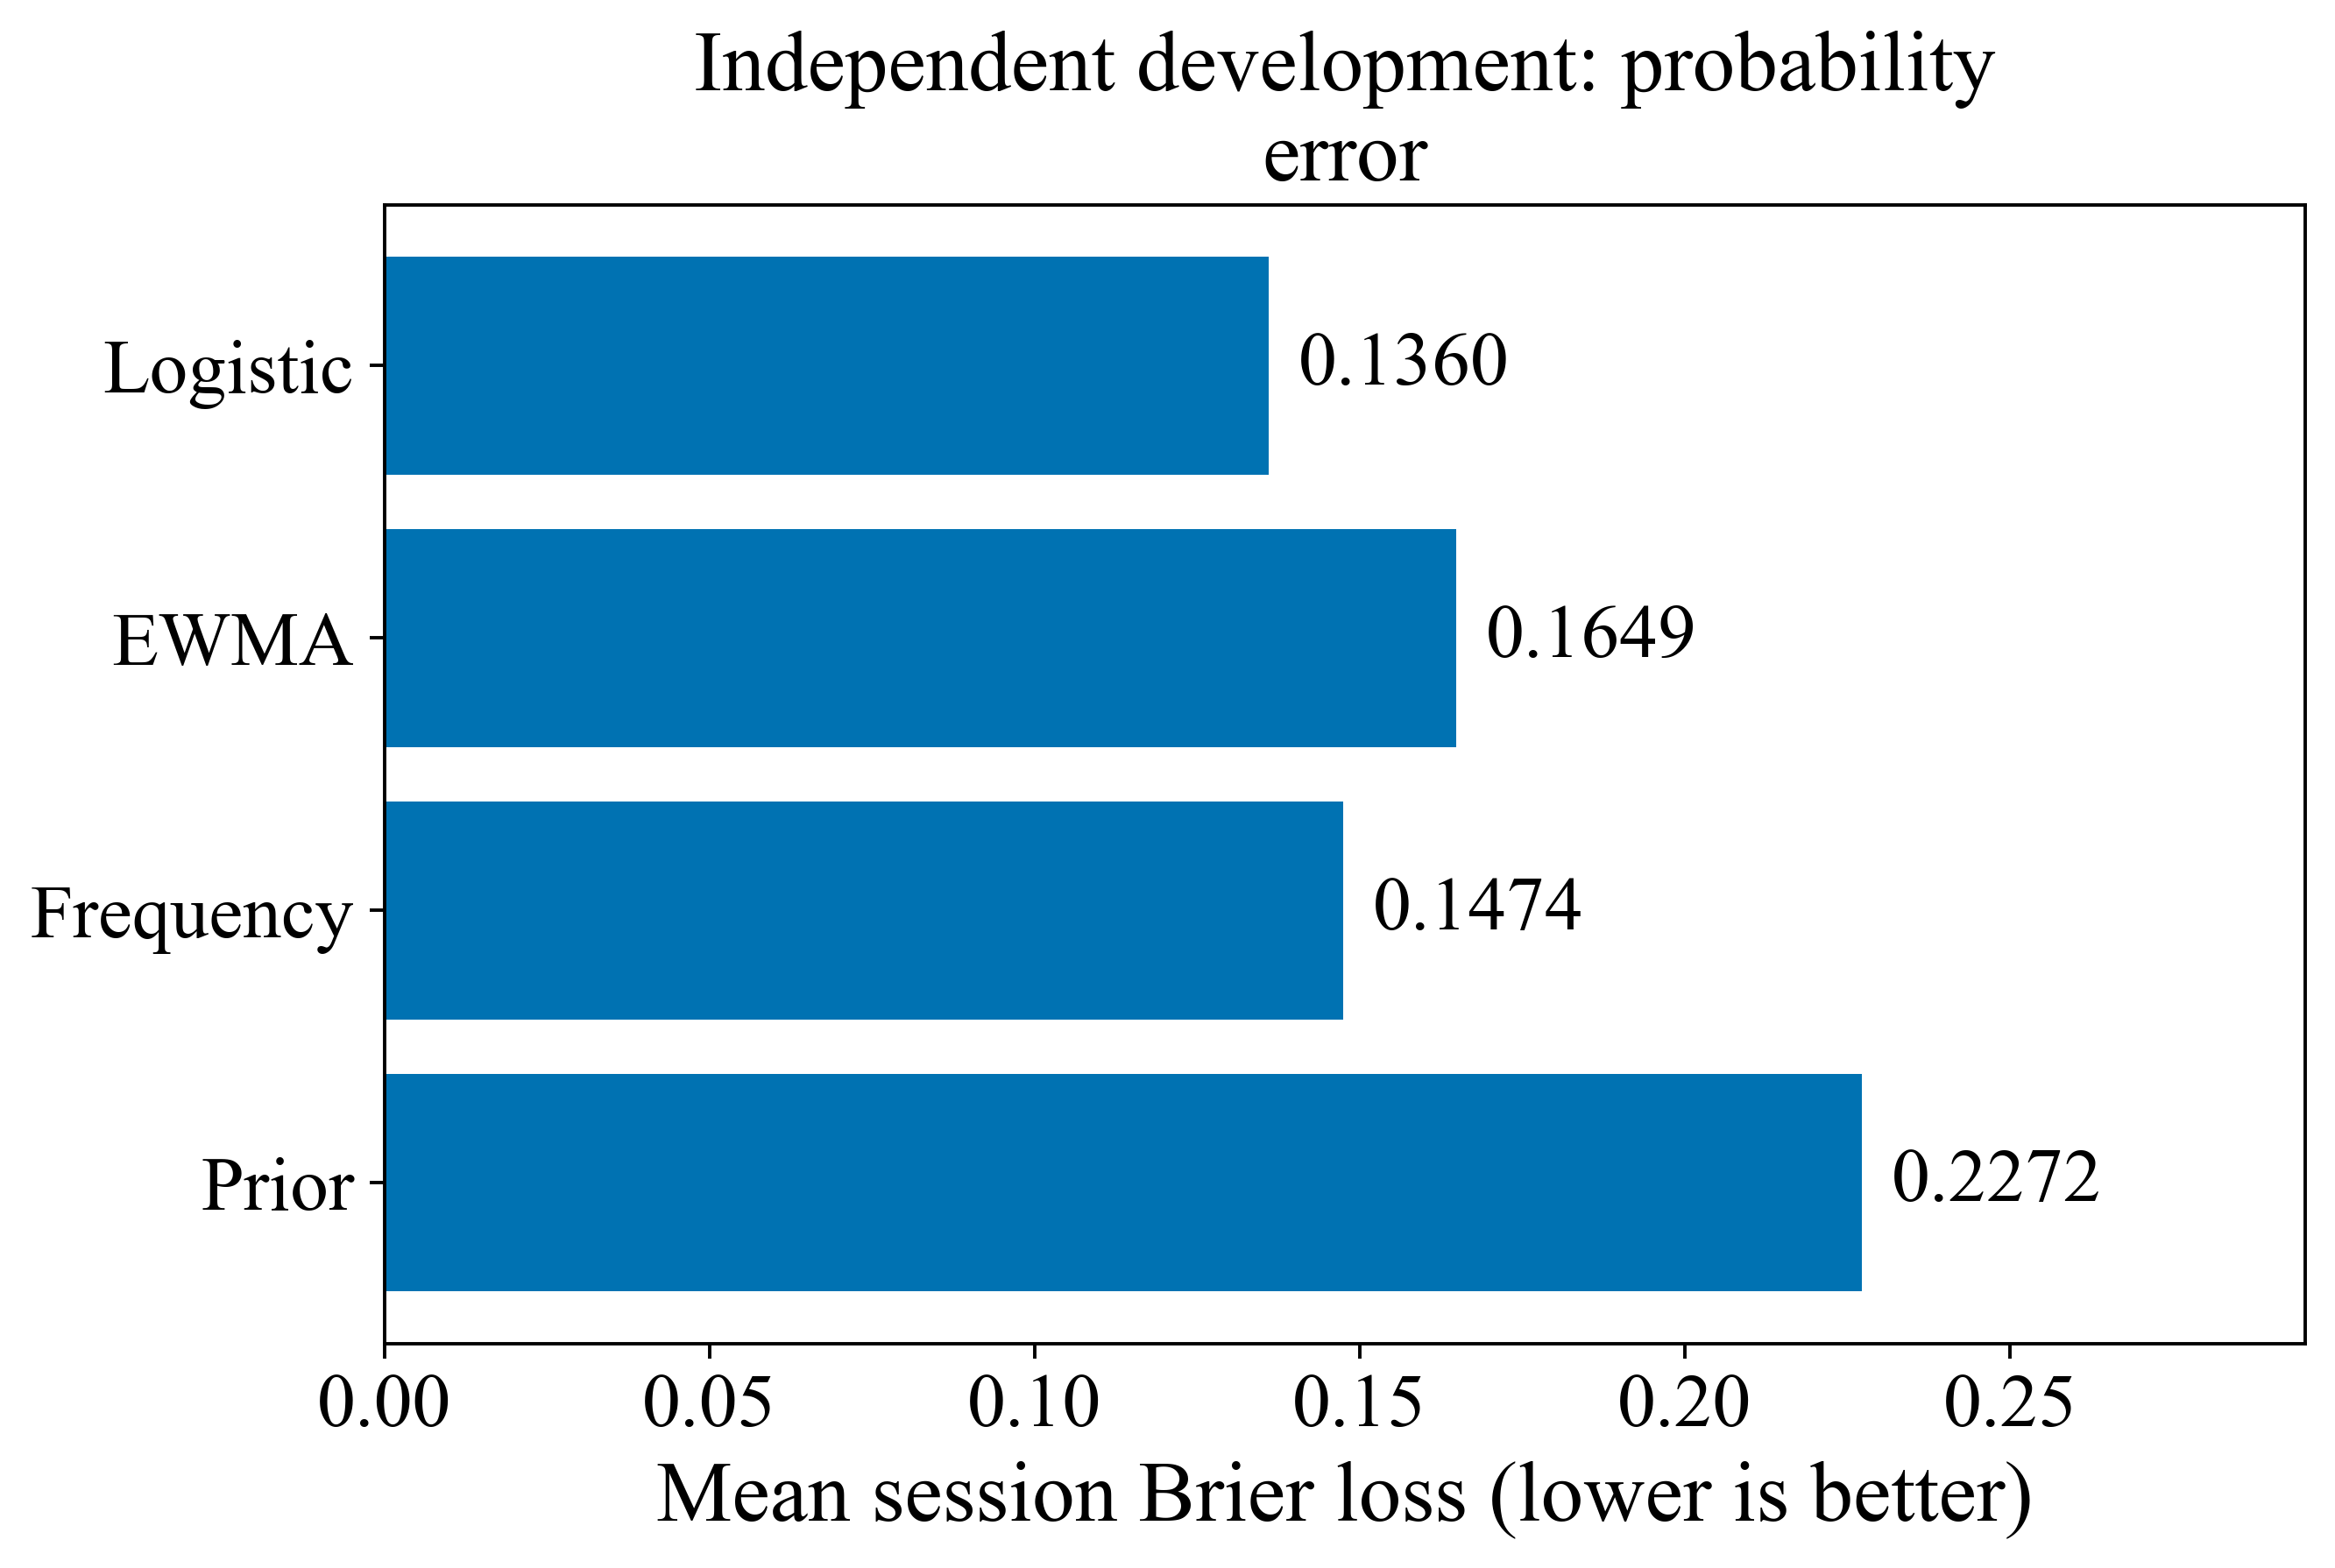

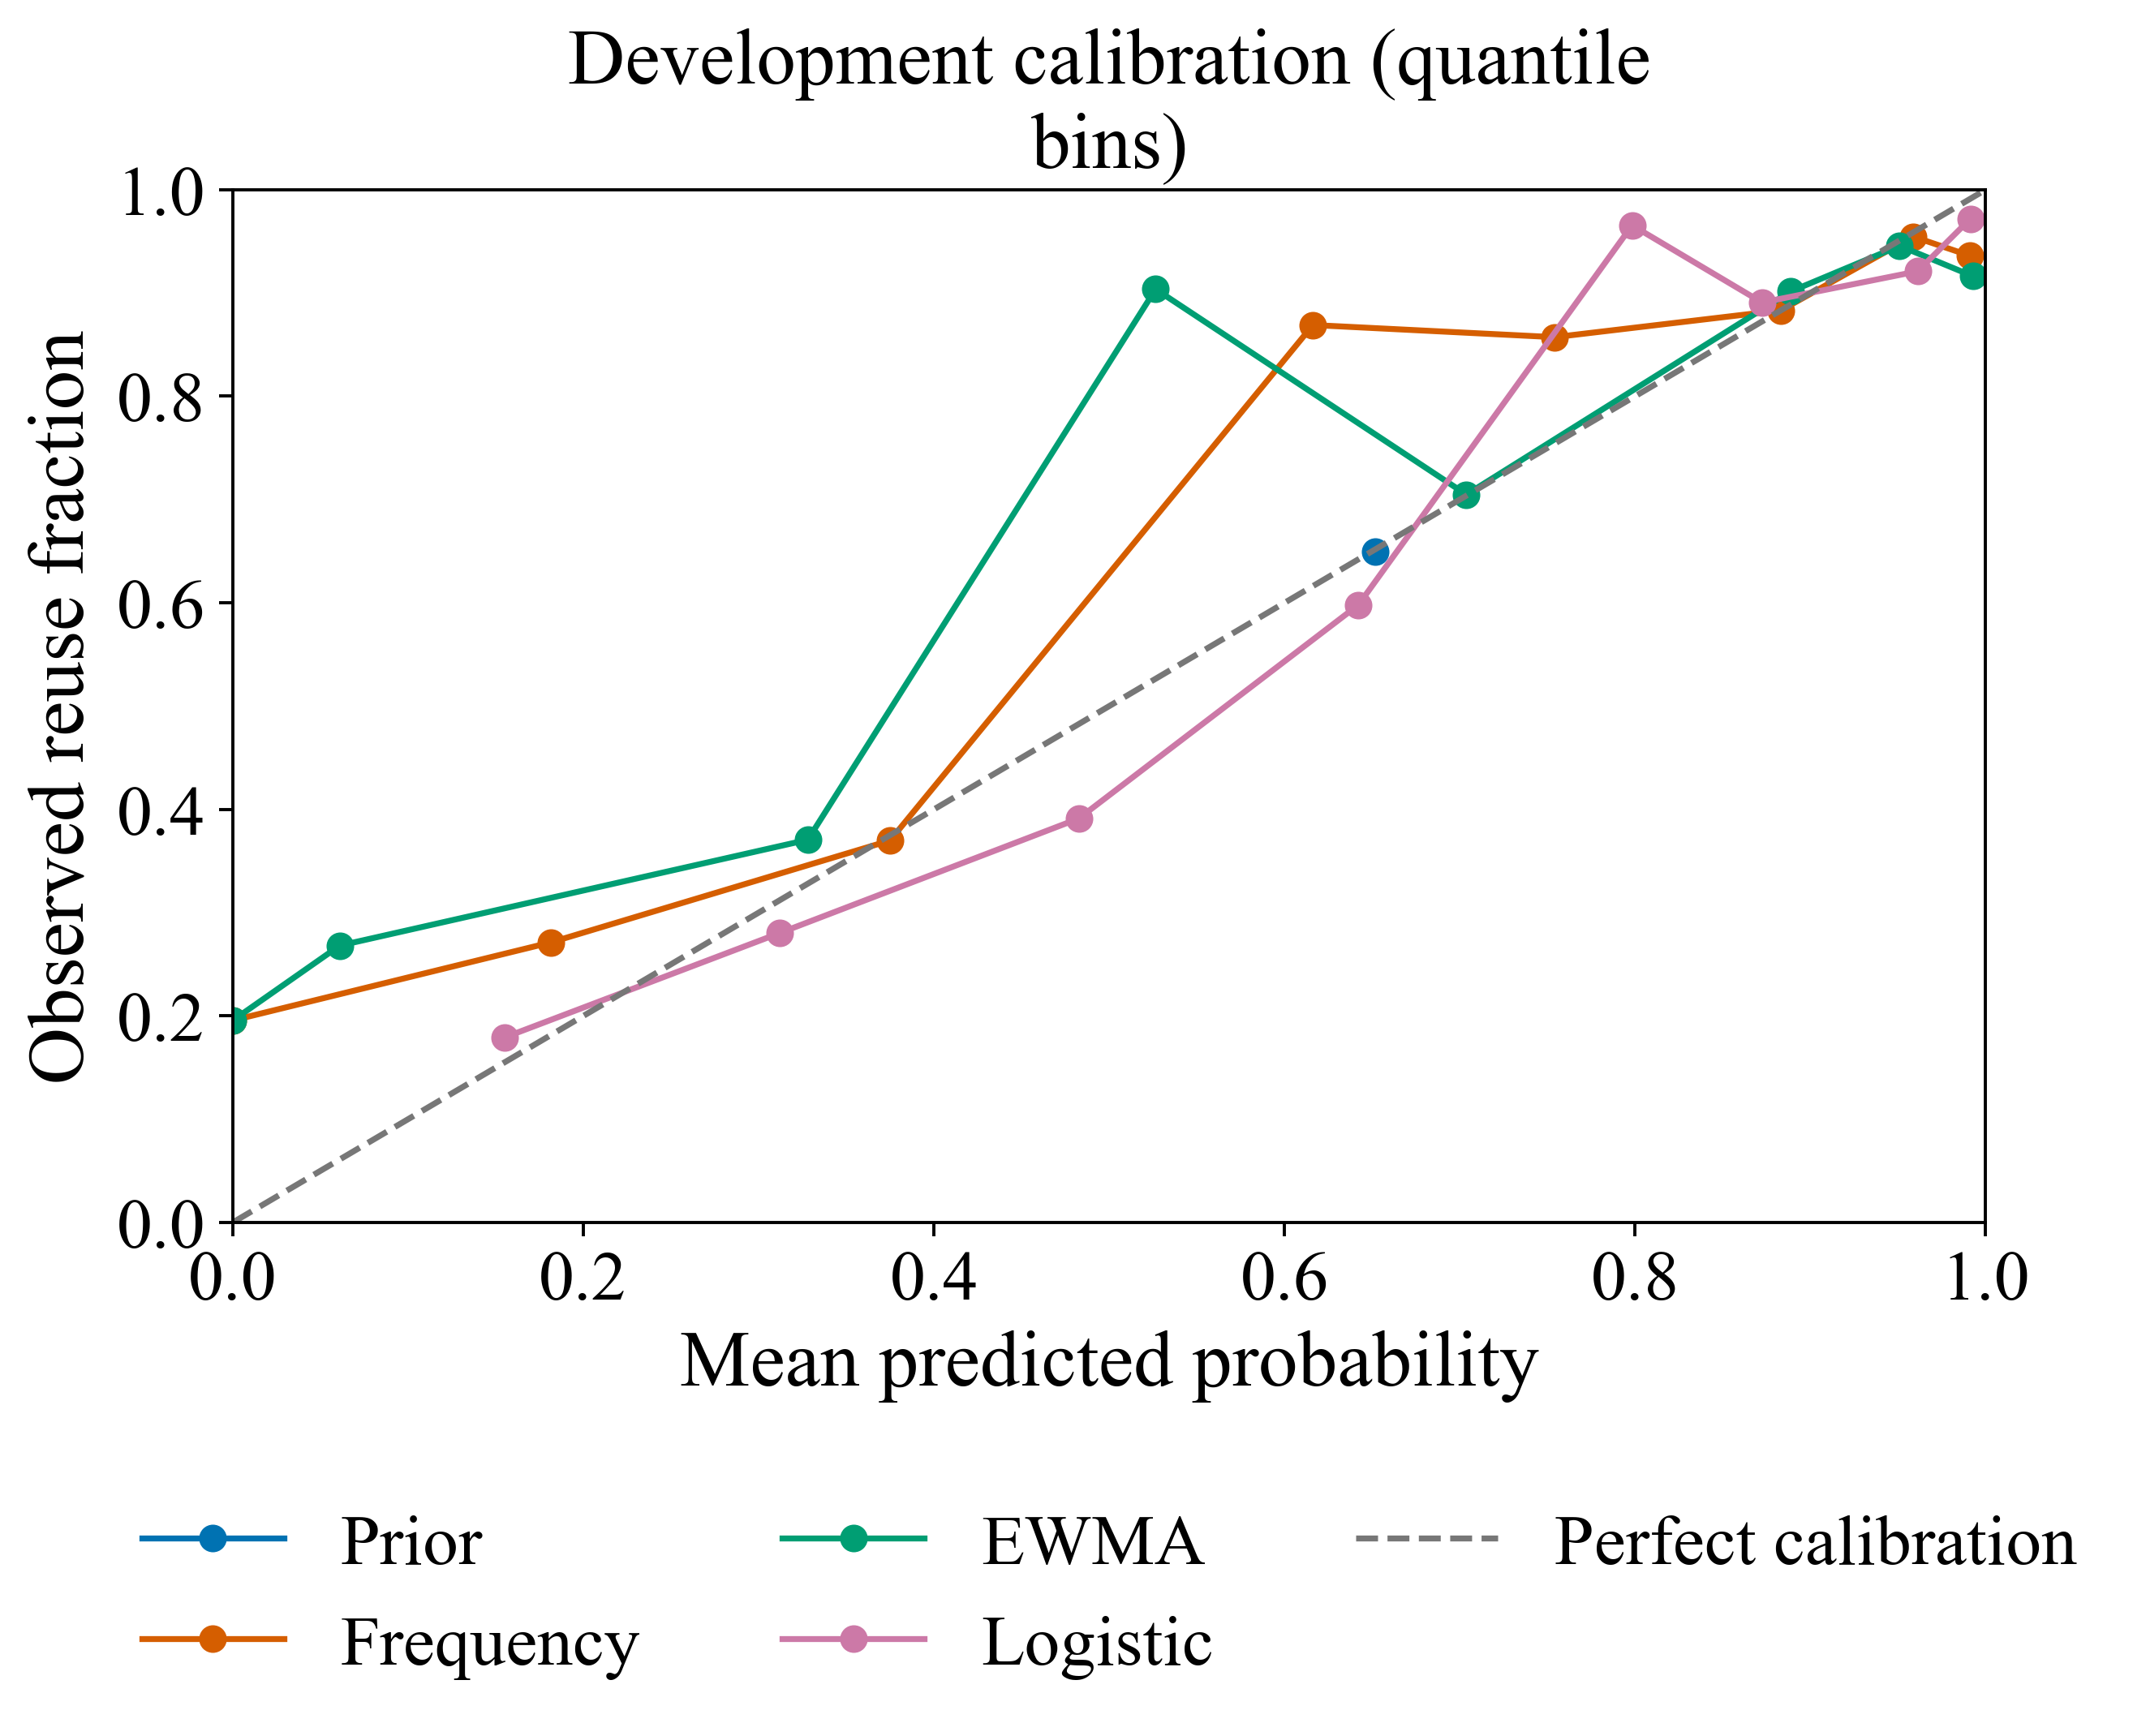

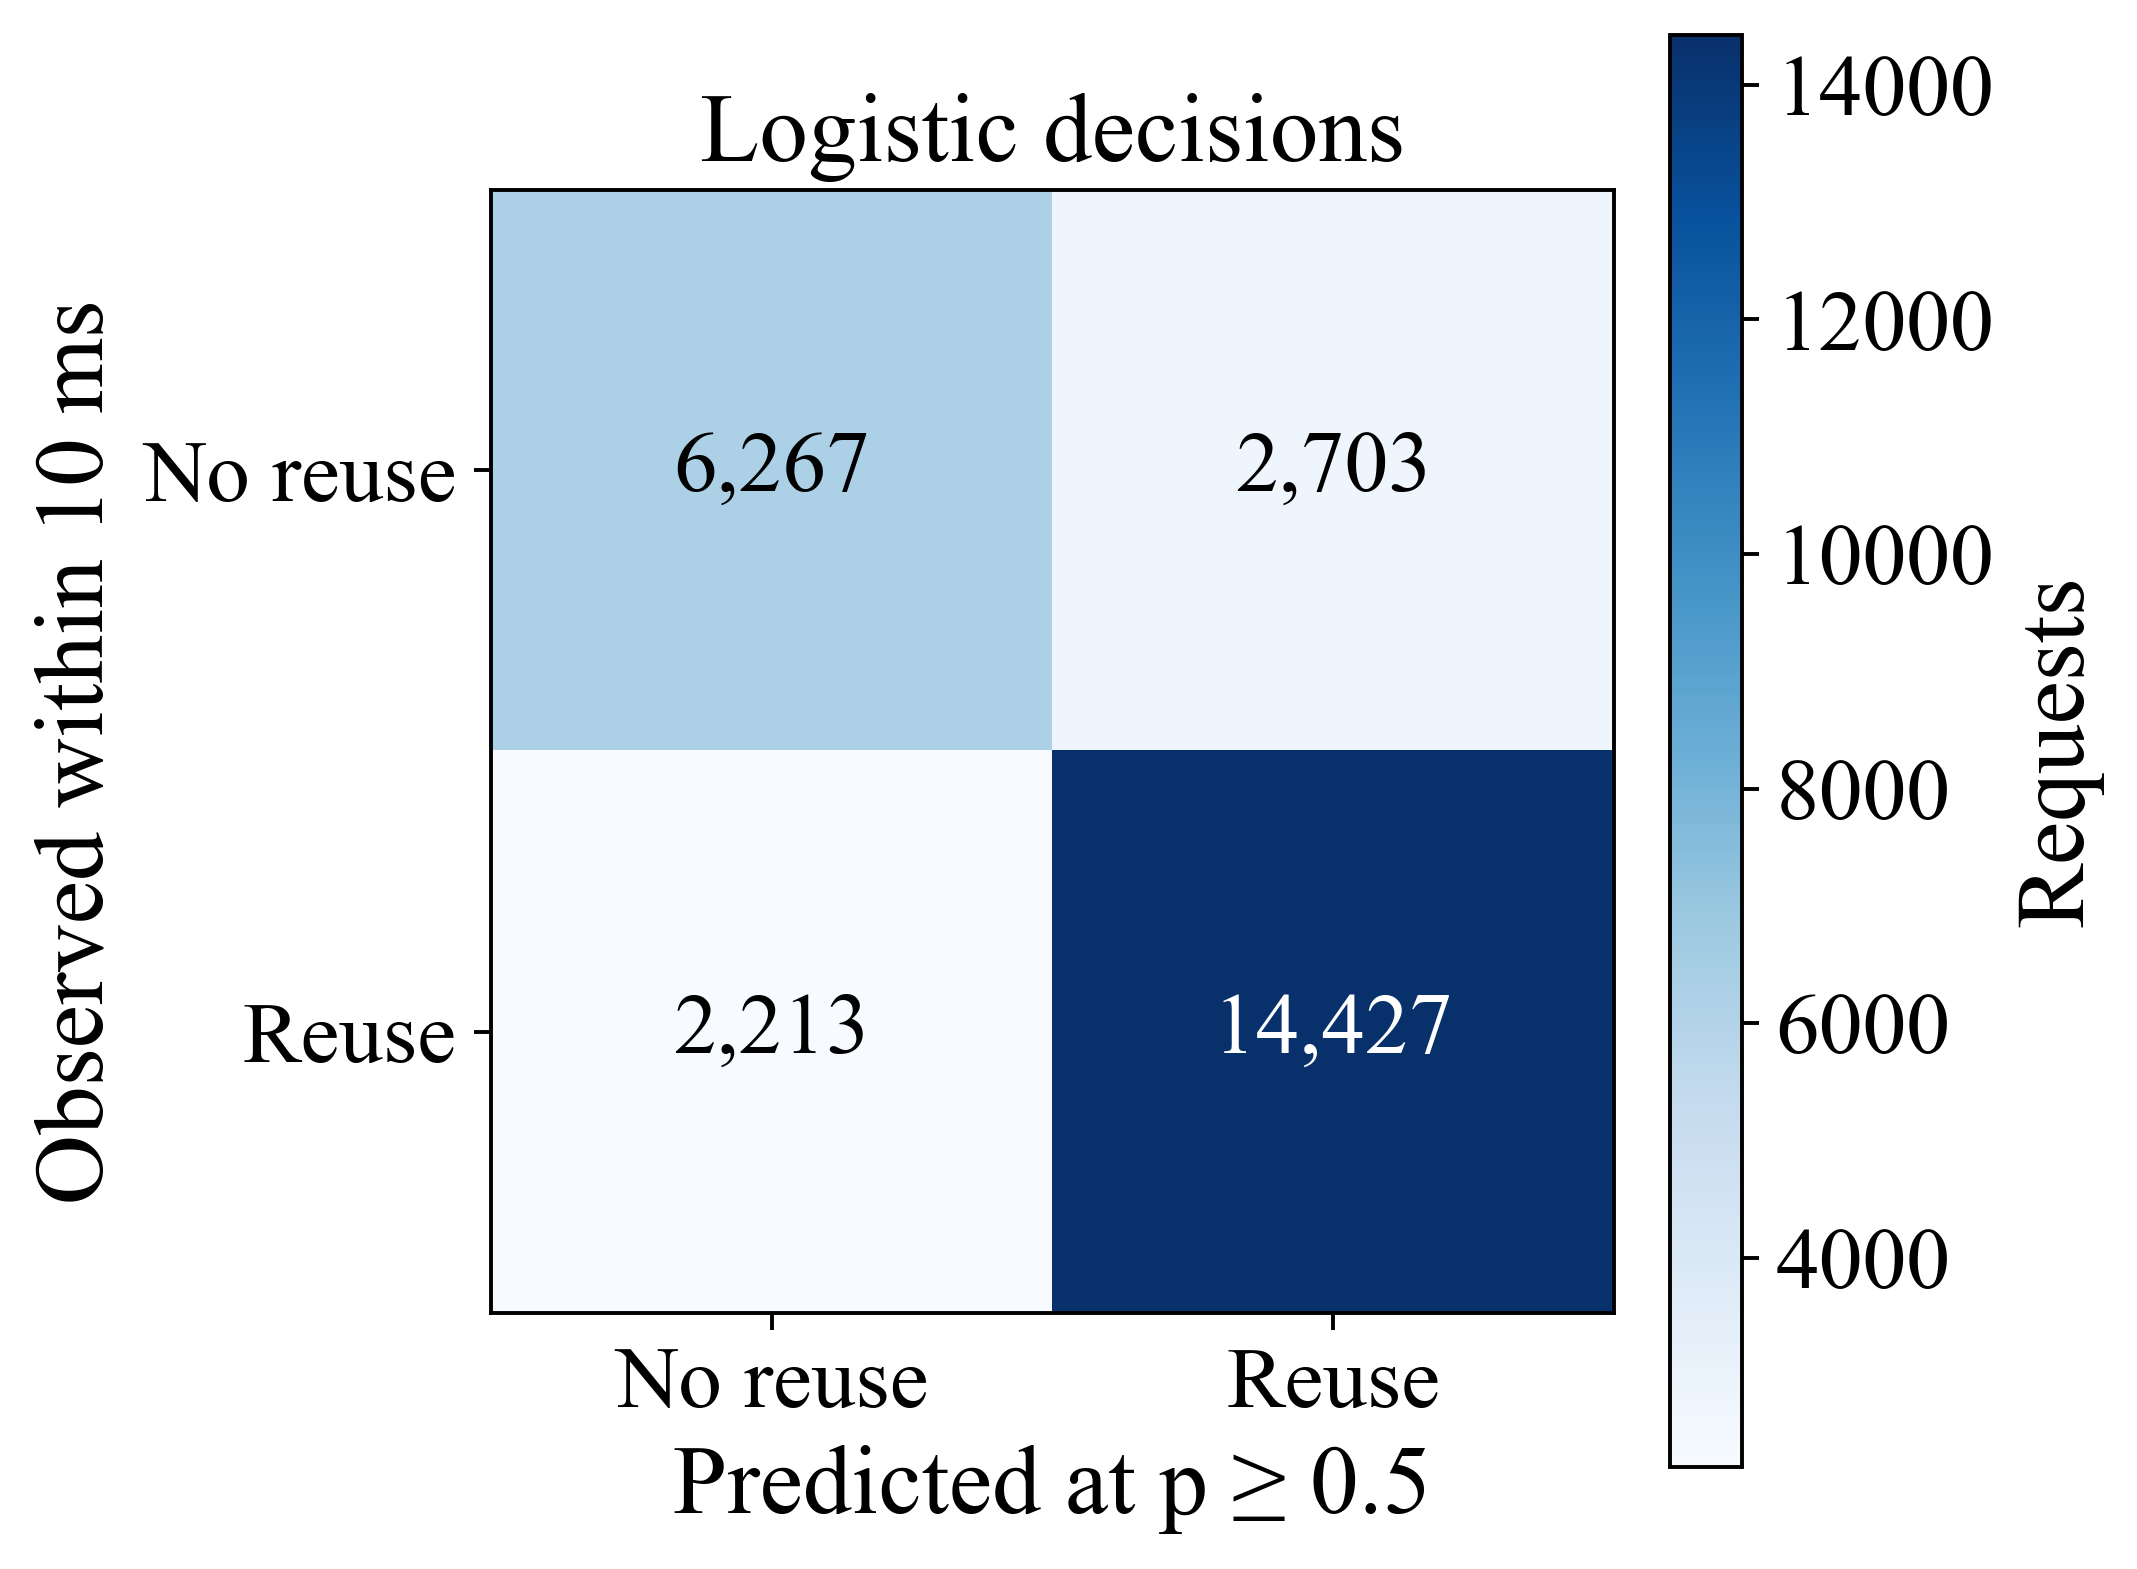

In [5]:
oof_metrics=[]
for (name,fold),q in oof.groupby(["model","fold"]):oof_metrics.append({"Model":name,"Fold":fold,**metrics(q,q.probability)})
save_table(pd.DataFrame(oof_metrics).set_index(["Model","Fold"]),"oof_metrics")
regime=[]
for (name,family),q in dev_predictions_long.groupby(["model","workload_id"]):regime.append({"Model":name,"Workload":family,**metrics(q,q.probability)})
regime=pd.DataFrame(regime)
save_table(regime.pivot(index="Workload",columns="Model",values="Brier_session_mean"),"regime_brier")
fig,ax=plt.subplots(figsize=(7.5,5.0))
score=pd.DataFrame([{ "Model":name,**metrics(dev,p)} for name,p in dev_predictions.items()]).set_index("Model")
bars=ax.barh(score.index,score.Brier_session_mean,color=COLORS[0]);ax.bar_label(bars,fmt="%.4f",padding=7,fontsize=18)
ax.set_xlim(0,score.Brier_session_mean.max()*1.3);ax.set(xlabel="Mean session Brier loss (lower is better)",title="Independent development: probability error")
save_figure(fig,"prediction_brier",score.reset_index())
fig,ax=plt.subplots(figsize=(7.4,6.0));calibration_rows=[]
for color,(name,p) in zip(COLORS,dev_predictions.items()):
    observed,predicted=calibration_curve(dev.y10.astype(int),p,n_bins=8,strategy="quantile")
    ax.plot(predicted,observed,marker="o",label=name,color=color)
    for x,y in zip(predicted,observed):calibration_rows.append({"model":name,"mean_predicted_probability":x,"observed_reuse_fraction":y})
ax.plot([0,1],[0,1],linestyle="--",color="#777777",label="Perfect calibration")
ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean predicted probability",ylabel="Observed reuse fraction",title="Development calibration (quantile bins)")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=3,frameon=False);fig.subplots_adjust(bottom=.28)
save_figure(fig,"calibration",pd.DataFrame(calibration_rows))
cm=confusion_matrix(dev.y10.astype(int),dev_predictions["Logistic"]>=.5,labels=[0,1])
fig,ax=plt.subplots(figsize=(6.0,5.2),layout="constrained");im=ax.imshow(cm,cmap="Blues")
for i in range(2):
    for j in range(2):ax.text(j,i,f"{cm[i,j]:,}",ha="center",va="center",fontsize=18,color="white" if cm[i,j]>cm.max()/2 else "black")
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["No reuse","Reuse"],yticklabels=["No reuse","Reuse"],xlabel="Predicted at p ≥ 0.5",ylabel="Observed within 10 ms",title="Logistic decisions")
fig.colorbar(im,ax=ax,label="Requests",shrink=.8)
save_figure(fig,"logistic_confusion",pd.DataFrame(cm,columns=["Predicted no reuse","Predicted reuse"]).rename_axis("Observed class").reset_index())



## 03.4 — Freeze baseline models and export a native predictor

The scaler and regression are algebraically folded into one linear score followed by a sigmoid. No inference is performed on the MacBook during native measured requests. Native and Python probabilities were compared on public feature rows when the campaign was acquired. A re-run refits the model locally and requires the exported header to match the pinned header byte for byte; the native checks are read from the saved summaries rather than repeated on the board.

In [6]:
joblib.dump(logistic,ARTIFACTS/"Models/logistic.joblib")
coef=logistic[-1].coef_[0]/logistic[0].scale_
intercept=float(logistic[-1].intercept_[0]-np.dot(logistic[-1].coef_[0],logistic[0].mean_/logistic[0].scale_))
model_spec={"type":"logistic","C":best_C,"features":FEATURES,"coefficient":coef.tolist(),"intercept":intercept,"training_rows":len(train),"training_sessions":train.session_id.nunique(),"primary_horizon_ms":10}
(ARTIFACTS/"Models/logistic.json").write_text(json.dumps(model_spec,indent=2)+"\n")
header="/* Exported by Notebook 03 from training-only model. */\n#include <math.h>\nstatic double predict_lr(const double*x){\n"
header+=f" double z={intercept:.17g};\n"
for i,v in enumerate(coef):header+=f" z+=({v:.17g})*x[{i}];\n"
header+=" return z>=0 ? 1.0/(1.0+exp(-z)) : exp(z)/(1.0+exp(z));\n}\n"
check_pinned_native_text("model_lr.h",header)
oof.to_parquet(ARTIFACTS/"Models/baseline_oof.parquet",index=False)
dev_predictions_long.to_parquet(ARTIFACTS/"Models/baseline_development_predictions.parquet",index=False)
save_table(pd.DataFrame({"feature":FEATURES,"native_coefficient":coef}).set_index("feature"),"logistic_coefficients")


,native_coefficient
feature,
c5,-0.219354
c10,0.300437
c20,-0.010543
c50,0.281206
gap50,-0.020773
gap_mean,-0.018821
gap_cv,-0.991504
exp10,-0.308023
share_shift,0.206459


## 03.5 — SSH orchestration and reproducible native builds

The host connection uses the project SSH configuration with a persistent control socket. During acquisition the native source, model coefficients and public validation features were copied to the Raspberry Pi and compiled there; on re-execution the acquisition branch stays inactive and no SSH command is issued. System packages and operating-system files are never replaced, and credentials are neither printed nor embedded in artifacts.

In [7]:
PI_SETUP=Path(os.environ.get("PI_SETUP_DIR","~/.scar_mlkem_pi")).expanduser()
SSH=["ssh","-F",str(PI_SETUP/"ssh_config"),"-S",str(PI_SETUP/"private/ssh_control"),"-o","BatchMode=yes","nazira-pi"]
REMOTE="/home/research/Nazira_Crystals-Cyber"
def remote(command,**kwargs):
    assert not CLOSED_NATIVE_REPLAY, "the archived campaign is analysed offline; SSH is not used"
    return subprocess.run(SSH+[command],check=True,text=True,capture_output=True,**kwargs)
def remote_sudo(command):
    # Authorized stored credential travels only through encrypted SSH stdin.
    auth=json.loads((PI_SETUP/"private/credentials.json").read_text())
    try:return remote("sudo -S -p '' sh -c "+shlex.quote(command),input=auth["password"]+"\n")
    finally:del auth

if not CLOSED_NATIVE_REPLAY:
    source_names=["cache_benchmark.c","build_cache.sh","microbench.c","build_microbench.sh","model_lr.h"]
    for name in source_names:
        remote("cat > "+shlex.quote(REMOTE+"/Native/"+name),input=(ROOT/"support/native"/name).read_text())
    build=remote("cd "+shlex.quote(REMOTE)+" && bash Native/build_cache.sh && bash Native/build_microbench.sh")
    (ROOT/"support/manifests/Runs/native_baseline_build.log").write_text(build.stdout+build.stderr)


## 03.6 — Native probability parity and baseline correctness gate

Cache residency is measured from reconstruction start to completed erasure. Every constrained policy uses the same 10 ms maximum age and a 200 µs early-erasure guard; ages are never renewed by hits. Expiry runs while waiting for arrivals as well as during processing. Linux scheduling can delay erasure: lateness is explicitly measured and must not be represented as a hard real-time guarantee. The budget controls active expanded-key material; the prototype additionally reserves a fixed locked arena, whose size is reported separately.

Seed-only, FIFO under fixed TTL, LRU and LFU are matched on input schedule, CPU affinity and cryptographic backend. Statistical/learned admissions use the stated probability rule and reject a lower-score candidate when full; this is a simple baseline, not SCAR. Model and feature costs are included in native request service time. The work endpoint used here sums wall-clock request service and timed idle expiry. It excludes the next-wake scan and sleep-entry/exit overhead, and is not exhaustive thread CPU time; Notebook 05 adopts complete request-phase thread CPU as the common endpoint.

In [8]:

if CLOSED_NATIVE_REPLAY:
    smoke=pd.read_csv(ROOT/"artifacts/03_cache_smoke.csv").set_index("Policy")
    assert len(smoke)==7 and smoke.Requests.eq(500).all() and smoke.Successful.eq(500).all()
    save_table(smoke,"cache_smoke")
else:
    # Compile a public-feature parity driver next to the generated header.
    driver='#include <stdio.h>\n#include "model_lr.h"\nint main(void){double x[11];while(scanf("%lf",&x[0])==1){for(int i=1;i<11;i++)if(scanf("%lf",&x[i])!=1)return 2;printf("%.17g\\n",predict_lr(x));}return 0;}\n'
    (ROOT/"support/native/predict_lr_check.c").write_text(driver)
    remote("cat > "+shlex.quote(REMOTE+"/Native/predict_lr_check.c"),input=driver)
    remote("cd "+shlex.quote(REMOTE)+" && gcc -O3 Native/predict_lr_check.c -lm -o Native/build/predict_lr_check")
    check=dev[FEATURES].iloc[::97]
    public_input="\n".join(" ".join(f"{v:.17g}" for v in row) for row in check.to_numpy())+"\n"
    native_p=np.fromstring(remote(REMOTE+"/Native/build/predict_lr_check",input=public_input).stdout,sep=" ")
    python_p=logistic.predict_proba(check)[:,1]
    assert native_p.shape==python_p.shape
    max_error=float(np.max(np.abs(native_p-python_p)));assert max_error<1e-12
    smoke=[]
    for policy in ["seed_only","fixed_ttl","lru","lfu","frequency","ewma","logistic"]:
        result=remote(f"taskset -c 2 {REMOTE}/Native/build/cache_benchmark smoke_{policy} thrashing 7771 500 64 500 development {policy} 16 10")
        q=pd.read_csv(io.StringIO(result.stdout));assert len(q)==500 and q.success.eq(1).all()
        assert q.cache_occupancy_bytes.le(16*2400).all()
        if policy in ["seed_only","lru"]:assert q.cache_hit.sum()==0
        (ROOT/"support/manifests/Validation"/f"cache_smoke_{policy}.txt").write_text(result.stderr)
        smoke.append({"Policy":policy,"Requests":len(q),"Successful":q.success.sum(),"Hits":q.cache_hit.sum(),"Maximum_active_cache_bytes":q.cache_occupancy_bytes.max()})
    save_table(pd.DataFrame(smoke).set_index("Policy"),"cache_smoke")


,Requests,Successful,Hits,Maximum_active_cache_bytes
Policy,,,,
seed_only,500,500,0,0
fixed_ttl,500,500,0,38400
lru,500,500,0,38400
lfu,500,500,0,38400
frequency,500,500,209,38400
ewma,500,500,209,38400
logistic,500,500,242,38400


## 03.7 — Cross-language feature parity and measured expiry checks

Predictions agree to numerical precision on public feature vectors. Feature extraction was additionally checked on one full development session per workload family, including the initial history; the result table is read from the saved summary rather than recomputed on the Raspberry Pi. Only eligible rows are compared with the frozen training representation. Cache smoke tests establish functional correctness and active-secret budget enforcement; they do not establish side-channel resistance or guaranteed real-time erasure.

In [9]:

if CLOSED_NATIVE_REPLAY:
    raw_events=pd.read_parquet(DATA/"interim/development_events.parquet")
    feature_parity=pd.read_csv(ROOT/"artifacts/03_native_feature_parity.csv").set_index("Workload")
    assert len(feature_parity)==10 and feature_parity.Passed.eq(True).all()
    save_table(feature_parity,"native_feature_parity")
    smoke_security=pd.read_csv(ROOT/"artifacts/03_smoke_security.csv").set_index("Policy")
    assert len(smoke_security)==7
    save_table(smoke_security,"smoke_security")
else:
    raw_events=pd.read_parquet(DATA/"interim/development_events.parquet")
    feature_parity=[]
    for family in sorted(dev.workload_id.unique()):
        sid=sorted(dev.loc[dev.workload_id.eq(family),"session_id"].unique())[0]
        q=raw_events.loc[raw_events.session_id.eq(sid)].sort_values("request_id")
        times=q.scheduled_arrival_ns.to_numpy()-q.scheduled_arrival_ns.iloc[0]
        payload="\n".join(f"{int(t)} {int(k)}" for t,k in zip(times,q.key_id))+"\n"
        output=remote(REMOTE+"/Native/build/cache_benchmark features",input=payload).stdout
        native_features=pd.read_csv(io.StringIO(output),header=None,names=FEATURES)
        expected=dev.loc[dev.session_id.eq(sid)].sort_values("request_id")
        actual=native_features.iloc[expected.request_id.to_numpy()].to_numpy()
        delta=np.abs(actual-expected[FEATURES].to_numpy())
        feature_parity.append({"Workload":family,"Rows":len(expected),"Maximum_absolute_difference":delta.max(),"Passed":np.allclose(actual,expected[FEATURES],rtol=1e-9,atol=1e-8)})
    feature_parity=pd.DataFrame(feature_parity).set_index("Workload")
    save_table(feature_parity,"native_feature_parity")
    assert feature_parity.Passed.all(),"Resolve any cross-language feature discrepancy before collecting policies"
    smoke_security=[]
    for path in sorted((ROOT/"support/manifests/Validation").glob("cache_smoke_*.txt")):
        values=dict(re.findall(r"([a-z_]+)=([^\s]+)",path.read_text()))
        smoke_security.append({"Policy":values["policy"],"Maximum_residency_ms":int(values["max_residency_ns"])/1e6,"Late_clear_events":int(values["late_clear_count"]),"Maximum_lateness_us":int(values["max_lateness_ns"])/1e3,"Verified_cache_zeroizations":int(values["cache_zeroizations"]),"Locked_arena_bytes":int(values["secrets_mlocked_bytes"])})
    save_table(pd.DataFrame(smoke_security).set_index("Policy"),"smoke_security")


,Rows,Maximum_absolute_difference,Passed
Workload,,,
abrupt,860,1.776357e-15,True
bursty,806,5.329071e-15,True
hotcold,860,1.776357e-15,True
nonstationary,860,1.776357e-15,True
periodic,860,8.881784e-16,True
poisson,861,3.552714e-15,True
thrashing,860,6.245005e-17,True
uniform,860,1.776357e-15,True
varying_contexts,860,1.776357e-15,True


,Maximum_residency_ms,Late_clear_events,Maximum_lateness_us,Verified_cache_zeroizations,Locked_arena_bytes
Policy,,,,,
ewma,9.860407,0,0.0,223,1189152
fixed_ttl,8.140890,0,0.0,500,1189152
frequency,9.856944,0,0.0,223,1189152
lfu,8.091464,0,0.0,500,1189152
logistic,9.866981,0,0.0,258,1189152
lru,8.113390,0,0.0,500,1189152
seed_only,0.000000,0,0.0,0,1189152


## 03.8 — Paired native development collection

Each policy receives the same scheduled context requests for each of the 30 development sessions. Policy order is rotated between sessions to reduce ordering bias. The CPU is pinned to core 2; the governor is temporarily set to `performance` and restored in `finally`. Temperature, frequency and throttle flags are saved; final validity is checked after collection. No OS upgrade or persistent governor setting is made.

This first matched series reproduces the original 1,000-request development schedules. Longer and rate/budget sensitivity runs follow after the baseline gate. Fresh secret seeds and encapsulation randomness use the OS CSPRNG independently of the public workload generator. The key-access sequence is paired; secret bytes need not be identical to compare timing. CSV records contain identifiers, durations and counters only. Source and binary hashes accompany the run. No energy is inferred.

The following cell verifies and loads the completed 210-run collection; the acquisition commands remain in the inactive branch for reference.

In [10]:
collection=RAW/"Baseline_development_v1"
if (collection/"SHA256SUMS").exists():
    for line in (collection/"SHA256SUMS").read_text().splitlines():
        expected,name=line.split(maxsplit=1)
        assert hashlib.sha256((collection/name).read_bytes()).hexdigest()==expected,name
    for rel,h in json.loads((collection/"source_hashes.json").read_text()).items():
        assert hashlib.sha256((ROOT/relocate(rel)).read_bytes()).hexdigest()==h,rel
else:
    POLICIES=["seed_only","fixed_ttl","lru","lfu","frequency","ewma","logistic"]
    collection=RAW/"Baseline_development_v1"
    collection.mkdir(exist_ok=True)
    manifest_rows=pd.read_csv(DATA/"splits/development_session_assignments.csv")
    manifest_rows=manifest_rows.loc[manifest_rows.split.eq("development")].sort_values("session_id")
    run_plan=[]
    for index,r in enumerate(manifest_rows.itertuples()):
        order=POLICIES[index%len(POLICIES):]+POLICIES[:index%len(POLICIES)]
        for order_index,policy in enumerate(order):
            run_plan.append({"session_id":r.session_id,"workload_id":r.workload_id,"workload_seed":r.workload_seed,"requests":1000,"key_contexts":r.key_contexts,"base_interval_us":500,"policy":policy,"order":order_index,"capacity":0 if policy=="seed_only" else 16,"ttl_ms":10})
    plan=pd.DataFrame(run_plan)
    plan_path=ROOT/"support/configs/baseline_native_plan.csv";plan.to_csv(plan_path,index=False)
    source_hashes={acquisition_path(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [ROOT/"support/native/cache_benchmark.c",ROOT/"support/native/build_cache.sh",ROOT/"support/native/microbench.c",ROOT/"support/native/build_microbench.sh",ROOT/"support/native/model_lr.h",plan_path]}
    (collection/"source_hashes.json").write_text(json.dumps(source_hashes,indent=2)+"\n")
    (collection/"native_binary_hashes.txt").write_text(remote(f"sha256sum {REMOTE}/Native/build/cache_benchmark {REMOTE}/Native/build/microbench").stdout)
    governor_path="/sys/devices/system/cpu/cpufreq/policy0/scaling_governor"
    old_governor=remote("cat "+governor_path).stdout.strip()
    assert old_governor in ["ondemand","performance","powersave","schedutil","conservative","userspace"]
    completed=[]
    try:
        remote_sudo("printf performance > "+governor_path)
        assert remote("cat "+governor_path).stdout.strip()=="performance"
        for session_index,(sid,part) in enumerate(plan.groupby("session_id",sort=False),1):
            for r in part.itertuples():
                stem=f"{r.session_id}__{r.policy}"
                dest=collection/(stem+".csv")
                assert not dest.exists(),f"Refusing to overwrite an existing raw run: {dest.name}"
                before=remote("vcgencmd get_throttled; cat /sys/devices/system/cpu/cpu2/cpufreq/scaling_cur_freq; cat /sys/class/thermal/thermal_zone0/temp").stdout
                command=f"taskset -c 2 {REMOTE}/Native/build/cache_benchmark {r.session_id} {r.workload_id} {r.workload_seed} {r.requests} {r.key_contexts} {r.base_interval_us} development {r.policy} {r.capacity} {r.ttl_ms}"
                result=remote(command)
                after=remote("vcgencmd get_throttled; cat /sys/devices/system/cpu/cpu2/cpufreq/scaling_cur_freq; cat /sys/class/thermal/thermal_zone0/temp").stdout
                dest.write_text(result.stdout)
                (collection/(stem+".meta")).write_text(result.stderr)
                (collection/(stem+".environment")).write_text("before\n"+before+"after\n"+after)
                frame=pd.read_csv(dest)
                assert len(frame)==r.requests and frame.success.eq(1).all()
                assert frame.cache_occupancy_bytes.le(r.capacity*2400).all()
                completed.append({**r._asdict(),"path":dest.name,"sha256":hashlib.sha256(dest.read_bytes()).hexdigest()})
        for repeat in range(1,7):
            sid=f"micro_controlled_{repeat}"
            result=remote(f"taskset -c 2 {REMOTE}/Native/build/microbench {sid} 3000")
            (collection/(sid+".csv")).write_text(result.stdout)
            (collection/(sid+".environment")).write_text(remote("vcgencmd get_throttled; cat /sys/devices/system/cpu/cpu2/cpufreq/scaling_cur_freq; cat /sys/class/thermal/thermal_zone0/temp").stdout)
    finally:
        remote_sudo("printf "+old_governor+" > "+governor_path)
        restored=remote("cat "+governor_path).stdout.strip()
        (collection/"governor_restore.json").write_text(json.dumps({"before":old_governor,"during":"performance","restored":restored},indent=2)+"\n")
        assert restored==old_governor
    pd.DataFrame(completed).to_csv(collection/"session_manifest.csv",index=False)
    files=sorted(p for p in collection.iterdir() if p.is_file() and p.name!="SHA256SUMS")
    (collection/"SHA256SUMS").write_text("".join(hashlib.sha256(p.read_bytes()).hexdigest()+"  "+p.name+"\n" for p in files))
    for p in collection.iterdir():
        if p.is_file():p.chmod(0o444)


## 03.6. Raw integrity, matched schedules and measurement quality

The unit of comparison is a matched workload session, not an individual request. All seven policies receive the same public schedule and context IDs; cryptographic randomness remains fresh and secret. The following cell verifies every checksum, every successful decapsulation and the exact schedules before aggregating. Active cache bytes, reserved locked arena bytes and whole-process peak RSS are separate quantities. Linux TTL compliance is measured, not assumed.

In [11]:
native_manifest=pd.read_csv(collection/"session_manifest.csv")
assert len(native_manifest)==210 and native_manifest.session_id.nunique()==30
for line in (collection/"SHA256SUMS").read_text().splitlines():
    expected,name=line.split(maxsplit=1)
    assert hashlib.sha256((collection/name).read_bytes()).hexdigest()==expected,name
POLICIES=["seed_only","fixed_ttl","lru","lfu","frequency","ewma","logistic"]
LABELS={"seed_only":"Seed-only","fixed_ttl":"Fixed TTL","lru":"LRU","lfu":"LFU","frequency":"Frequency","ewma":"EWMA","logistic":"Logistic"}
frames=[];quality=[];session_rows=[]
for r in native_manifest.itertuples():
    q=pd.read_csv(collection/r.path)
    assert len(q)==1000 and q.success.eq(1).all() and q.policy.eq(r.policy).all()
    ref=raw_events.loc[raw_events.session_id.eq(r.session_id)].sort_values("request_id")
    assert np.array_equal(q.key_id,ref.key_id)
    assert np.array_equal(q.schedule_ns-q.schedule_ns.iloc[0],ref.scheduled_arrival_ns-ref.scheduled_arrival_ns.iloc[0])
    assert q.cache_occupancy_bytes.le(r.capacity*2400).all()
    assert (q.cache_hit.eq(1)==q.reconstruction_ns.eq(0)).all()
    stem=Path(r.path).stem
    meta=dict(re.findall(r"([a-z_]+)=([^\s]+)",(collection/(stem+".meta")).read_text()))
    env=(collection/(stem+".environment")).read_text()
    throttle=re.findall(r"throttled=(0x[0-9a-f]+)",env)
    assert len(throttle)==2
    quality.append({"Session":r.session_id,"Policy":r.policy,"Temperature_min_C":q.temperature_c.min(),"Temperature_max_C":q.temperature_c.max(),"Frequency_min_MHz":q.cpu_frequency_mhz.min(),"Frequency_max_MHz":q.cpu_frequency_mhz.max(),"Throttling_flag":any(int(x,16)!=0 for x in throttle),"Late_clears":int(meta["late_clear_count"]),"Max_lifetime_ms":int(meta["max_residency_ns"])/1e6,"Max_lateness_us":int(meta["max_lateness_ns"])/1e3})
    elapsed_ns=q.schedule_ns.iloc[-1]-q.schedule_ns.iloc[0]+q.response_ns.iloc[-1]
    row={"session_id":r.session_id,"workload_id":r.workload_id,"policy":r.policy,"requests":len(q),"hit_rate":q.cache_hit.mean(),"miss_rate":1-q.cache_hit.mean(),"reconstructions":int(q.reconstruction_ns.gt(0).sum()),"service_mean_us":q.service_ns.mean()/1e3,"service_p95_us":q.service_ns.quantile(.95)/1e3,"service_p99_us":q.service_ns.quantile(.99)/1e3,"response_mean_us":q.response_ns.mean()/1e3,"response_p99_us":q.response_ns.quantile(.99)/1e3,"amortized_work_us":(q.service_ns+q.idle_maintenance_ns).mean()/1e3,"arrival_throughput_req_s":len(q)*1e9/elapsed_ns,"cycles_mean":q.cpu_cycles.mean(),"prediction_mean_us":q.prediction_ns.mean()/1e3,"lookup_mean_us":q.lookup_ns.mean()/1e3,"copy_mean_us":q.copy_ns.mean()/1e3,"clear_mean_us":q.clear_ns.mean()/1e3,"idle_maintenance_mean_us":q.idle_maintenance_ns.mean()/1e3,"sampled_cache_mean_bytes":q.cache_occupancy_bytes.mean(),"cache_max_bytes":q.cache_occupancy_bytes.max(),"expanded_key_byte_seconds":2400*int(meta["summed_residency_ns"])/1e9,"max_lifetime_ms":int(meta["max_residency_ns"])/1e6,"late_clears":int(meta["late_clear_count"]),"max_lateness_us":int(meta["max_lateness_ns"])/1e3,"locked_arena_bytes":int(meta["secrets_mlocked_bytes"]),"peak_rss_bytes":int(meta["peak_rss_bytes"]),"zeroizations":int(meta["cache_zeroizations"]),"evictions":q.evictions.sum()}
    session_rows.append(row);frames.append(q)
native_events=pd.concat(frames,ignore_index=True);native_metrics=pd.DataFrame(session_rows);quality=pd.DataFrame(quality)
assert not native_events.duplicated(["session_id","policy","request_id"]).any()
native_events.to_parquet(REPLAY_DIR/"Interim/baseline_native_events.parquet",index=False)
native_metrics.to_csv(REPLAY_DIR/"Interim/baseline_native_session_metrics.csv",index=False)
quality.to_csv(TABLES/"03_native_quality_all_sessions.csv",index=False)
quality_summary=quality.groupby("Policy").agg(Runs=("Session","size"),Temperature_min_C=("Temperature_min_C","min"),Temperature_max_C=("Temperature_max_C","max"),Frequency_min_MHz=("Frequency_min_MHz","min"),Frequency_max_MHz=("Frequency_max_MHz","max"),Flagged_runs=("Throttling_flag","sum"),Late_clears=("Late_clears","sum"),Maximum_lifetime_ms=("Max_lifetime_ms","max"),Maximum_lateness_us=("Max_lateness_us","max")).reindex(POLICIES)
save_table(quality_summary,"native_quality_summary")

,Runs,Temperature_min_C,Temperature_max_C,Frequency_min_MHz,Frequency_max_MHz,Flagged_runs,Late_clears,Maximum_lifetime_ms,Maximum_lateness_us
Policy,,,,,,,,,
seed_only,30,46.30,52.90,2400.0,2400.0,0,0,0.000000,0.0
fixed_ttl,30,46.30,53.45,2400.0,2400.0,0,0,9.886898,0.0
lru,30,46.85,52.90,2400.0,2400.0,0,0,9.865824,0.0
lfu,30,46.85,53.45,2400.0,2400.0,0,0,9.863305,0.0
frequency,30,46.85,52.90,2400.0,2400.0,0,0,9.855398,0.0
ewma,30,46.85,52.90,2400.0,2400.0,0,0,9.863897,0.0
logistic,30,47.40,53.45,2400.0,2400.0,0,0,9.866435,0.0


**Observed conditions.** All 210,000 decapsulations succeeded and all 210 matched schedules and checksums passed. Sampled CPU frequency was 2,400 MHz throughout; temperatures ranged from 46.30 to 53.45 °C. No before/after throttle flags were set. The largest observed expanded-key lifetime was 9.886898 ms under the 10 ms setting, with zero recorded late clears. These finite runs do not establish a hard real-time worst-case bound.

## 03.7. Native ML-KEM primitive costs

Each row below averages six independent process-session summaries, each containing 3,000 post-warmup measurements. The standard deviation describes between-session variability; it is not a confidence interval. KeyGen and Encaps include operating-system randomness. Reconstruction is deterministic expansion from an existing seed. The logarithmic axis exposes timer and erasure costs without hiding their much smaller scale.

,Session_p95_mean_us,Session_p99_mean_us,Sessions
Operation,,,
Seed reconstruction,21.034000,21.093028,6
KeyGen + RNG,21.071000,21.142363,6
Encaps + RNG,24.170000,24.241227,6
Decaps,29.691833,29.792190,6
"Erase 2,400 bytes",0.075000,0.075000,6
Timer pair,0.037000,0.038000,6


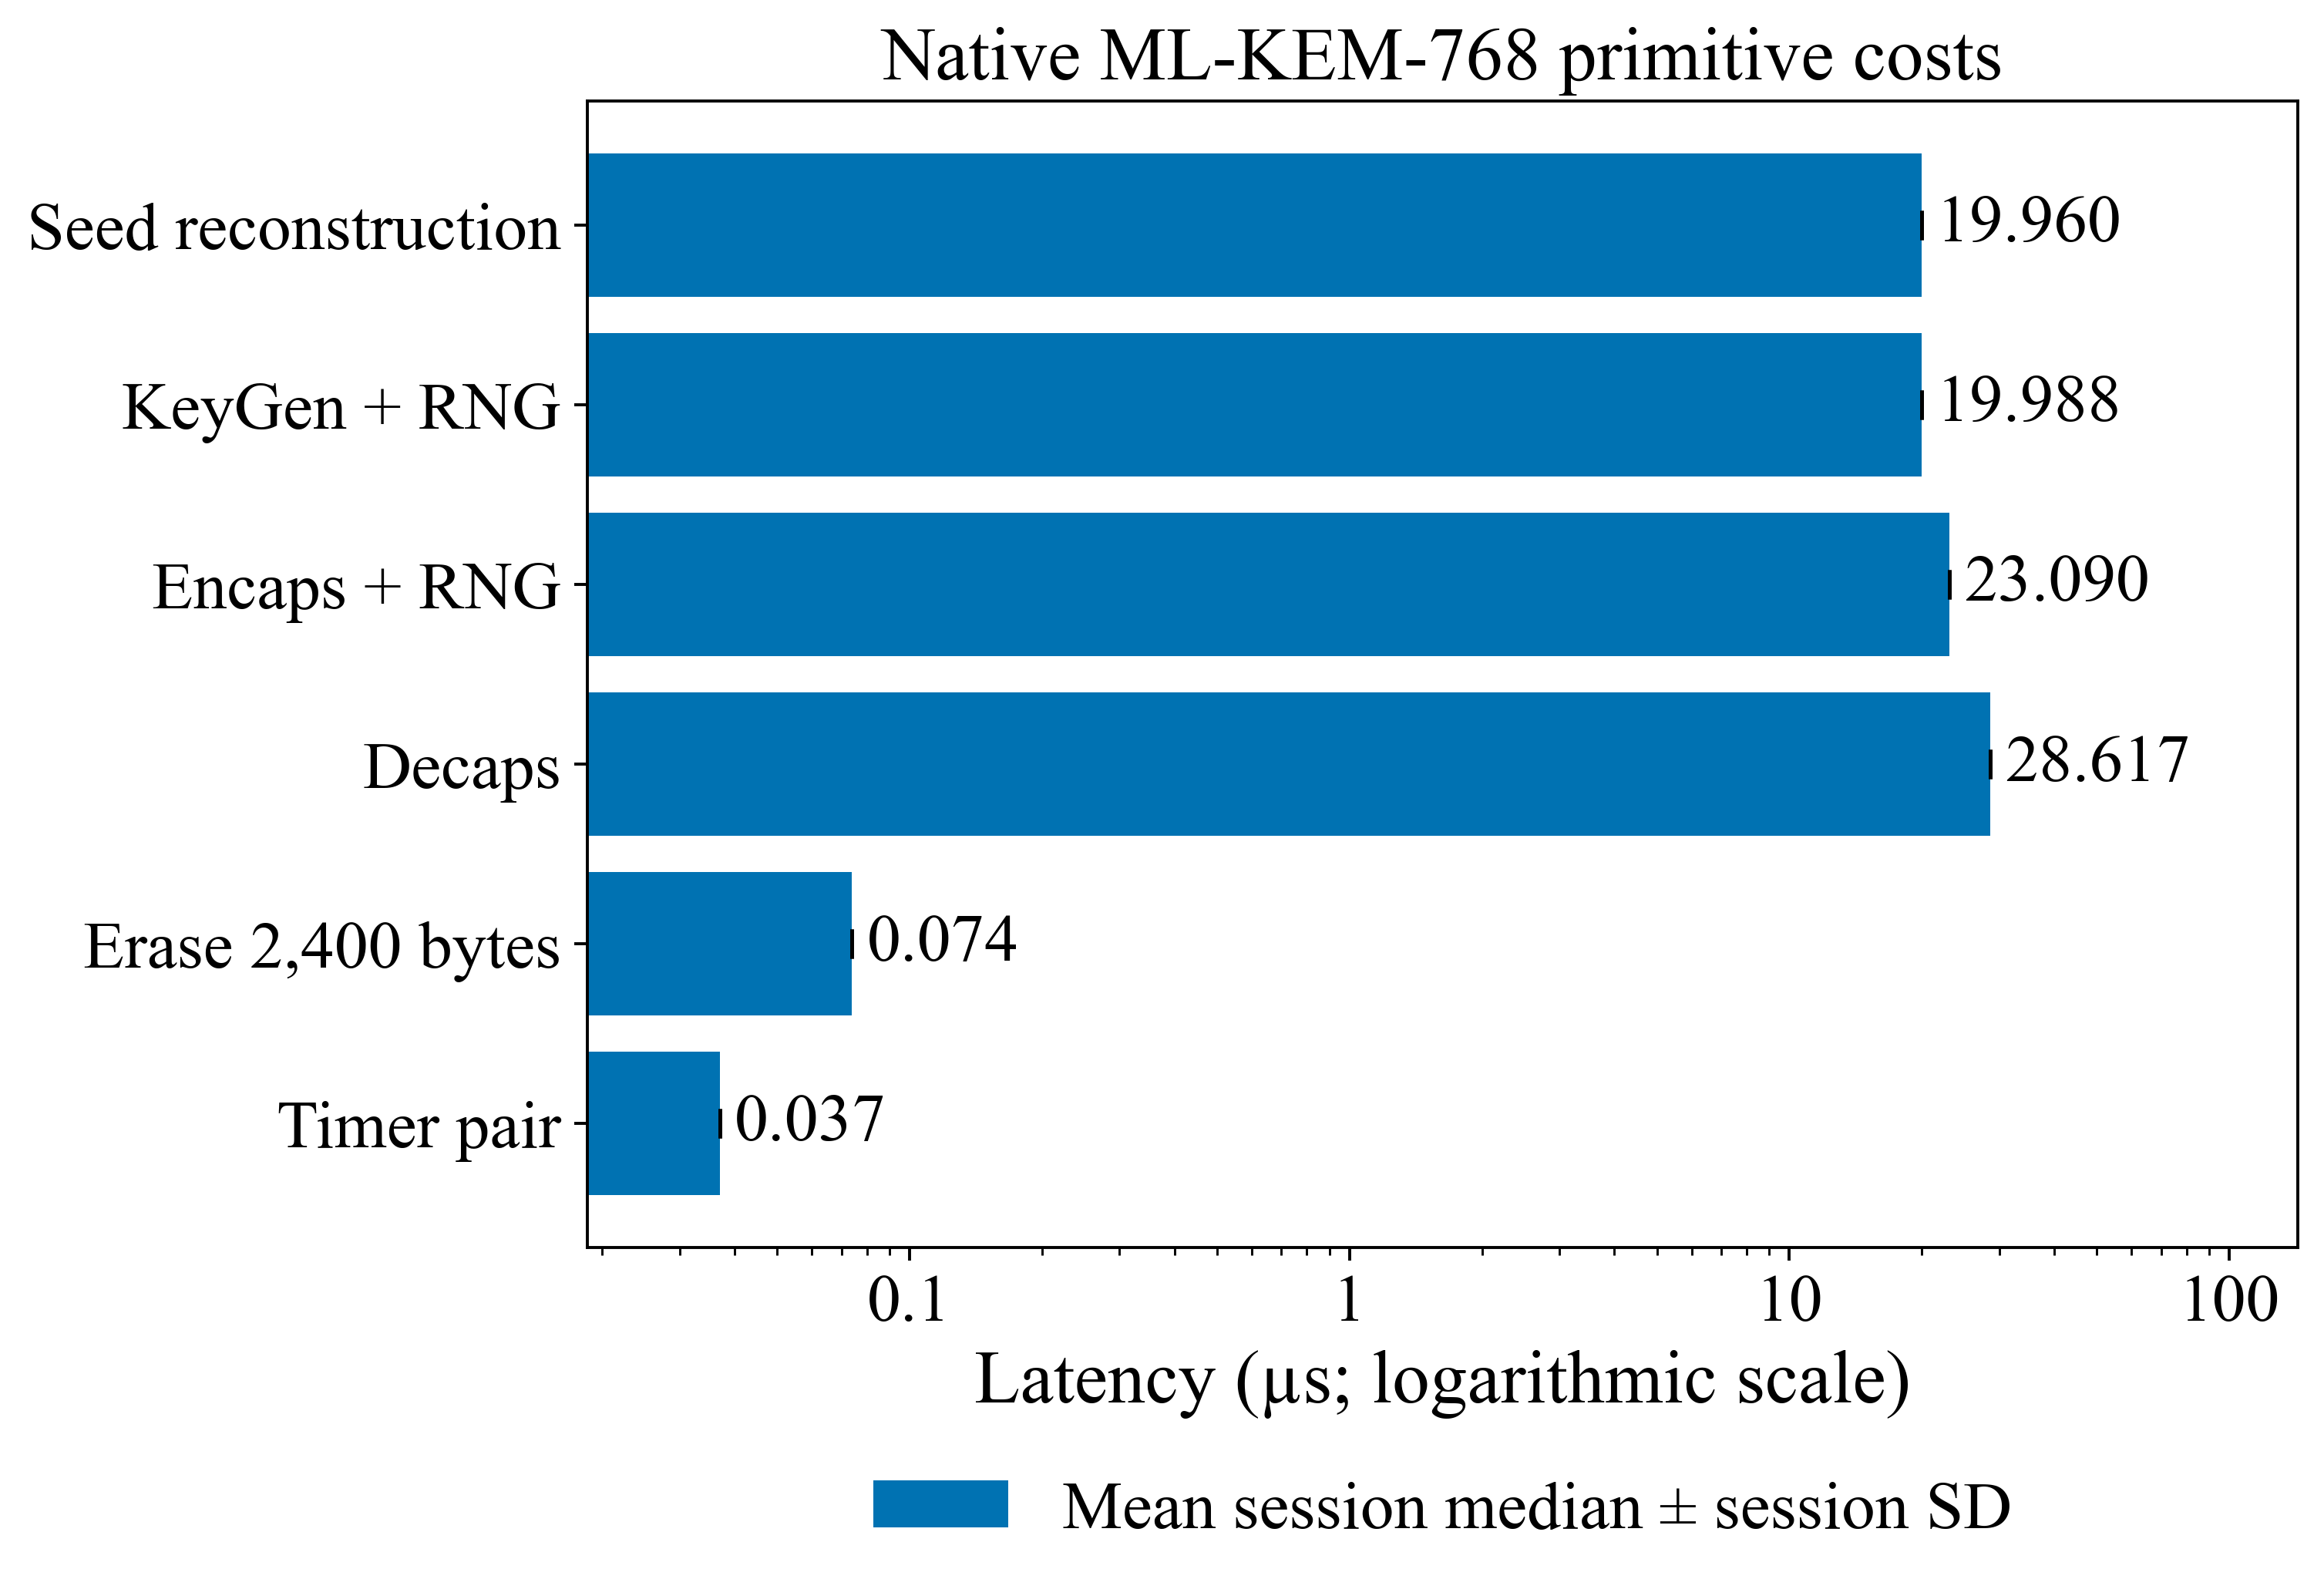

In [12]:
micro=pd.concat([pd.read_csv(p) for p in sorted(collection.glob("micro_controlled_*.csv"))],ignore_index=True)
assert len(micro)==18000 and micro.session_id.nunique()==6
MICRO_LABELS={"reconstruction_ns":"Seed reconstruction","keygen_with_rng_ns":"KeyGen + RNG","encaps_with_rng_ns":"Encaps + RNG","decaps_ns":"Decaps","zeroize_2400_ns":"Erase 2,400 bytes","timer_pair_ns":"Timer pair"}
micro_rows=[]
for name in MICRO_LABELS:
    per=micro.groupby("session_id")[name].agg(median="median",p95=lambda x:x.quantile(.95),p99=lambda x:x.quantile(.99))/1e3
    micro_rows.append({"Operation":MICRO_LABELS[name],"Session_median_mean_us":per["median"].mean(),"Session_median_SD_us":per["median"].std(),"Session_p95_mean_us":per.p95.mean(),"Session_p99_mean_us":per.p99.mean(),"Sessions":len(per)})
micro_summary=pd.DataFrame(micro_rows).set_index("Operation")
save_table(micro_summary,"native_microbenchmarks", exclude=['Session_median_mean_us', 'Session_median_SD_us'])
fig,ax=plt.subplots(figsize=(8.5,5.8),layout="constrained")
v=micro_summary.Session_median_mean_us;sd=micro_summary.Session_median_SD_us
bars=ax.barh(v.index,v,color=COLORS[0],xerr=sd,capsize=4,label="Mean session median ± session SD")
from matplotlib.ticker import FuncFormatter, NullFormatter
ax.set_xscale("log");ax.xaxis.set_major_formatter(FuncFormatter(lambda value,position:f"{value:g}"));ax.xaxis.set_minor_formatter(NullFormatter());ax.set_xlim(max(.001,v.min()/2),v.max()*5.0)
for y,(value,err) in enumerate(zip(v,sd)):ax.text((value+err)*1.08,y,f"{value:.3f}",va="center")
ax.invert_yaxis();ax.set_xlabel("Latency (µs; logarithmic scale)");ax.set_title("Native ML-KEM-768 primitive costs")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.15),frameon=False)
save_figure(fig,"native_microbenchmarks",micro_summary.reset_index())

**Primitive interpretation.** The mean session-median reconstruction cost was 19.960 µs, versus 28.618 µs for decapsulation. Reusing a resident key can therefore avoid a substantial operation, but cannot eliminate decapsulation. Explicit 2,400-byte erasure was 0.074 µs and the timer-pair baseline 0.037 µs; neither is subtracted from reported end-to-end measurements.

## 03.8. Complete baseline cost and memory accounting

Each policy receives equal weight across the 30 matched sessions (three per workload family). Amortized work adds expiry maintenance outside request service to the measured request service. It excludes waiting and SSH transfer. Achieved throughput is computed over the scheduled arrival-to-final-response interval; it is load-limited and is not a saturation-capacity claim. The fixed maximum secret arena reservation includes test fixtures; active cache occupancy is reported separately.

,hit_rate,miss_rate,reconstructions,service_mean_us,service_p95_us,service_p99_us
policy,,,,,,
seed_only,0.000000,1.000000,1000.000000,50.196970,51.461907,52.338594
fixed_ttl,0.450200,0.549800,549.800000,41.776281,51.919395,52.981687
lru,0.449867,0.550133,550.133333,41.785299,51.964345,53.127586
lfu,0.448067,0.551933,551.933333,41.667149,51.822682,52.891062
frequency,0.391600,0.608400,608.400000,42.979978,51.734322,53.001233
ewma,0.410500,0.589500,589.500000,42.634760,51.950478,53.136695
logistic,0.436867,0.563133,563.133333,42.091830,51.624985,52.827859


,response_mean_us,response_p99_us,arrival_throughput_req_s,cycles_mean
policy,,,,
seed_only,101.541398,110.152872,2008.154361,118263.096500
fixed_ttl,93.166312,110.786766,2008.191477,97950.941367
lru,93.166284,110.845988,2008.194417,98000.848800
lfu,92.973491,110.508640,2008.198691,97785.628133
frequency,94.597173,110.855775,2008.191806,100960.068367
ewma,94.178161,110.973754,2008.192049,100144.450500
logistic,93.610859,110.647607,2008.192151,98842.437700


,sampled_cache_mean_bytes,mean_session_peak_cache_bytes,expanded_key_byte_seconds,locked_arena_bytes,mean_session_peak_rss_bytes,evictions,zeroizations
policy,,,,,,,
seed_only,0.00,0.0,0.000000,1749152.0,5423104.0,0.000000,0.000000
fixed_ttl,25064.16,32320.0,12208.815368,1749152.0,5423104.0,186.933333,549.800000
lru,25060.48,32320.0,12200.454230,1749152.0,5423104.0,178.766667,550.133333
lfu,24904.16,32320.0,12093.215884,1749152.0,5423104.0,133.033333,551.933333
frequency,9134.40,17360.0,4359.927259,1749152.0,5423104.0,0.300000,186.766667
ewma,10438.48,19440.0,4971.992281,1749152.0,5423104.0,0.300000,212.966667
logistic,12856.24,28320.0,6123.504752,1749152.0,5423104.0,1.000000,262.300000


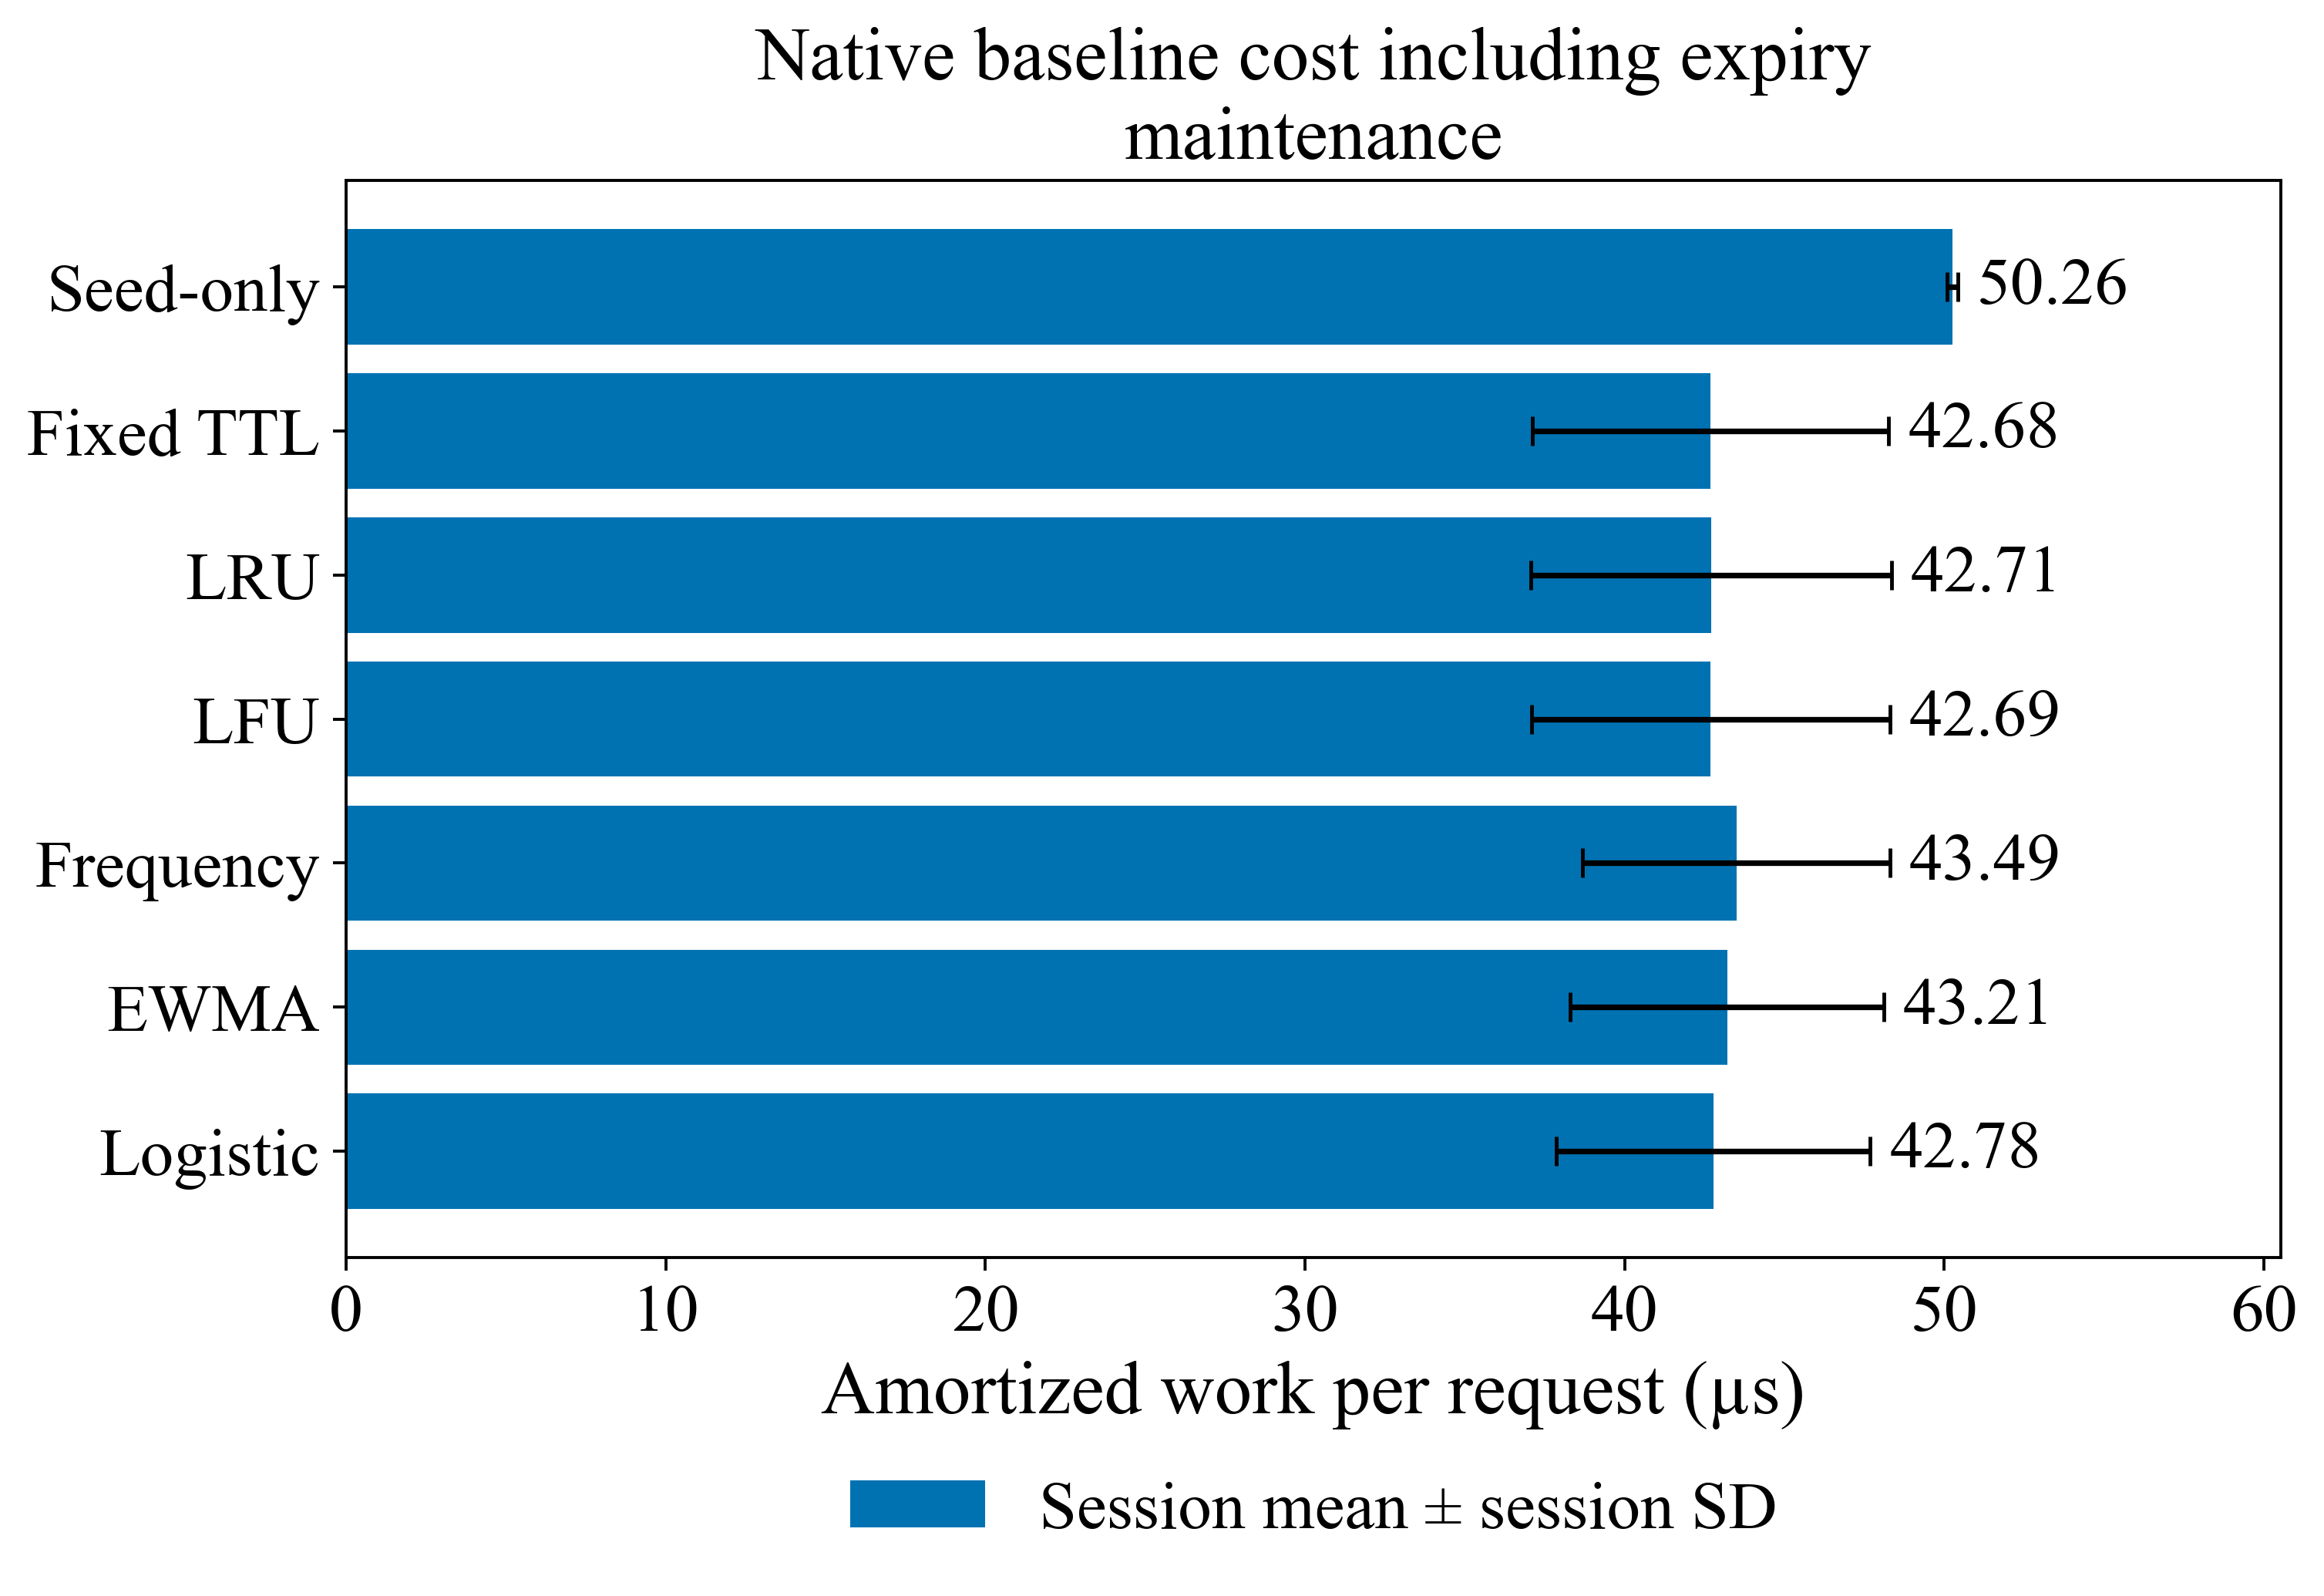

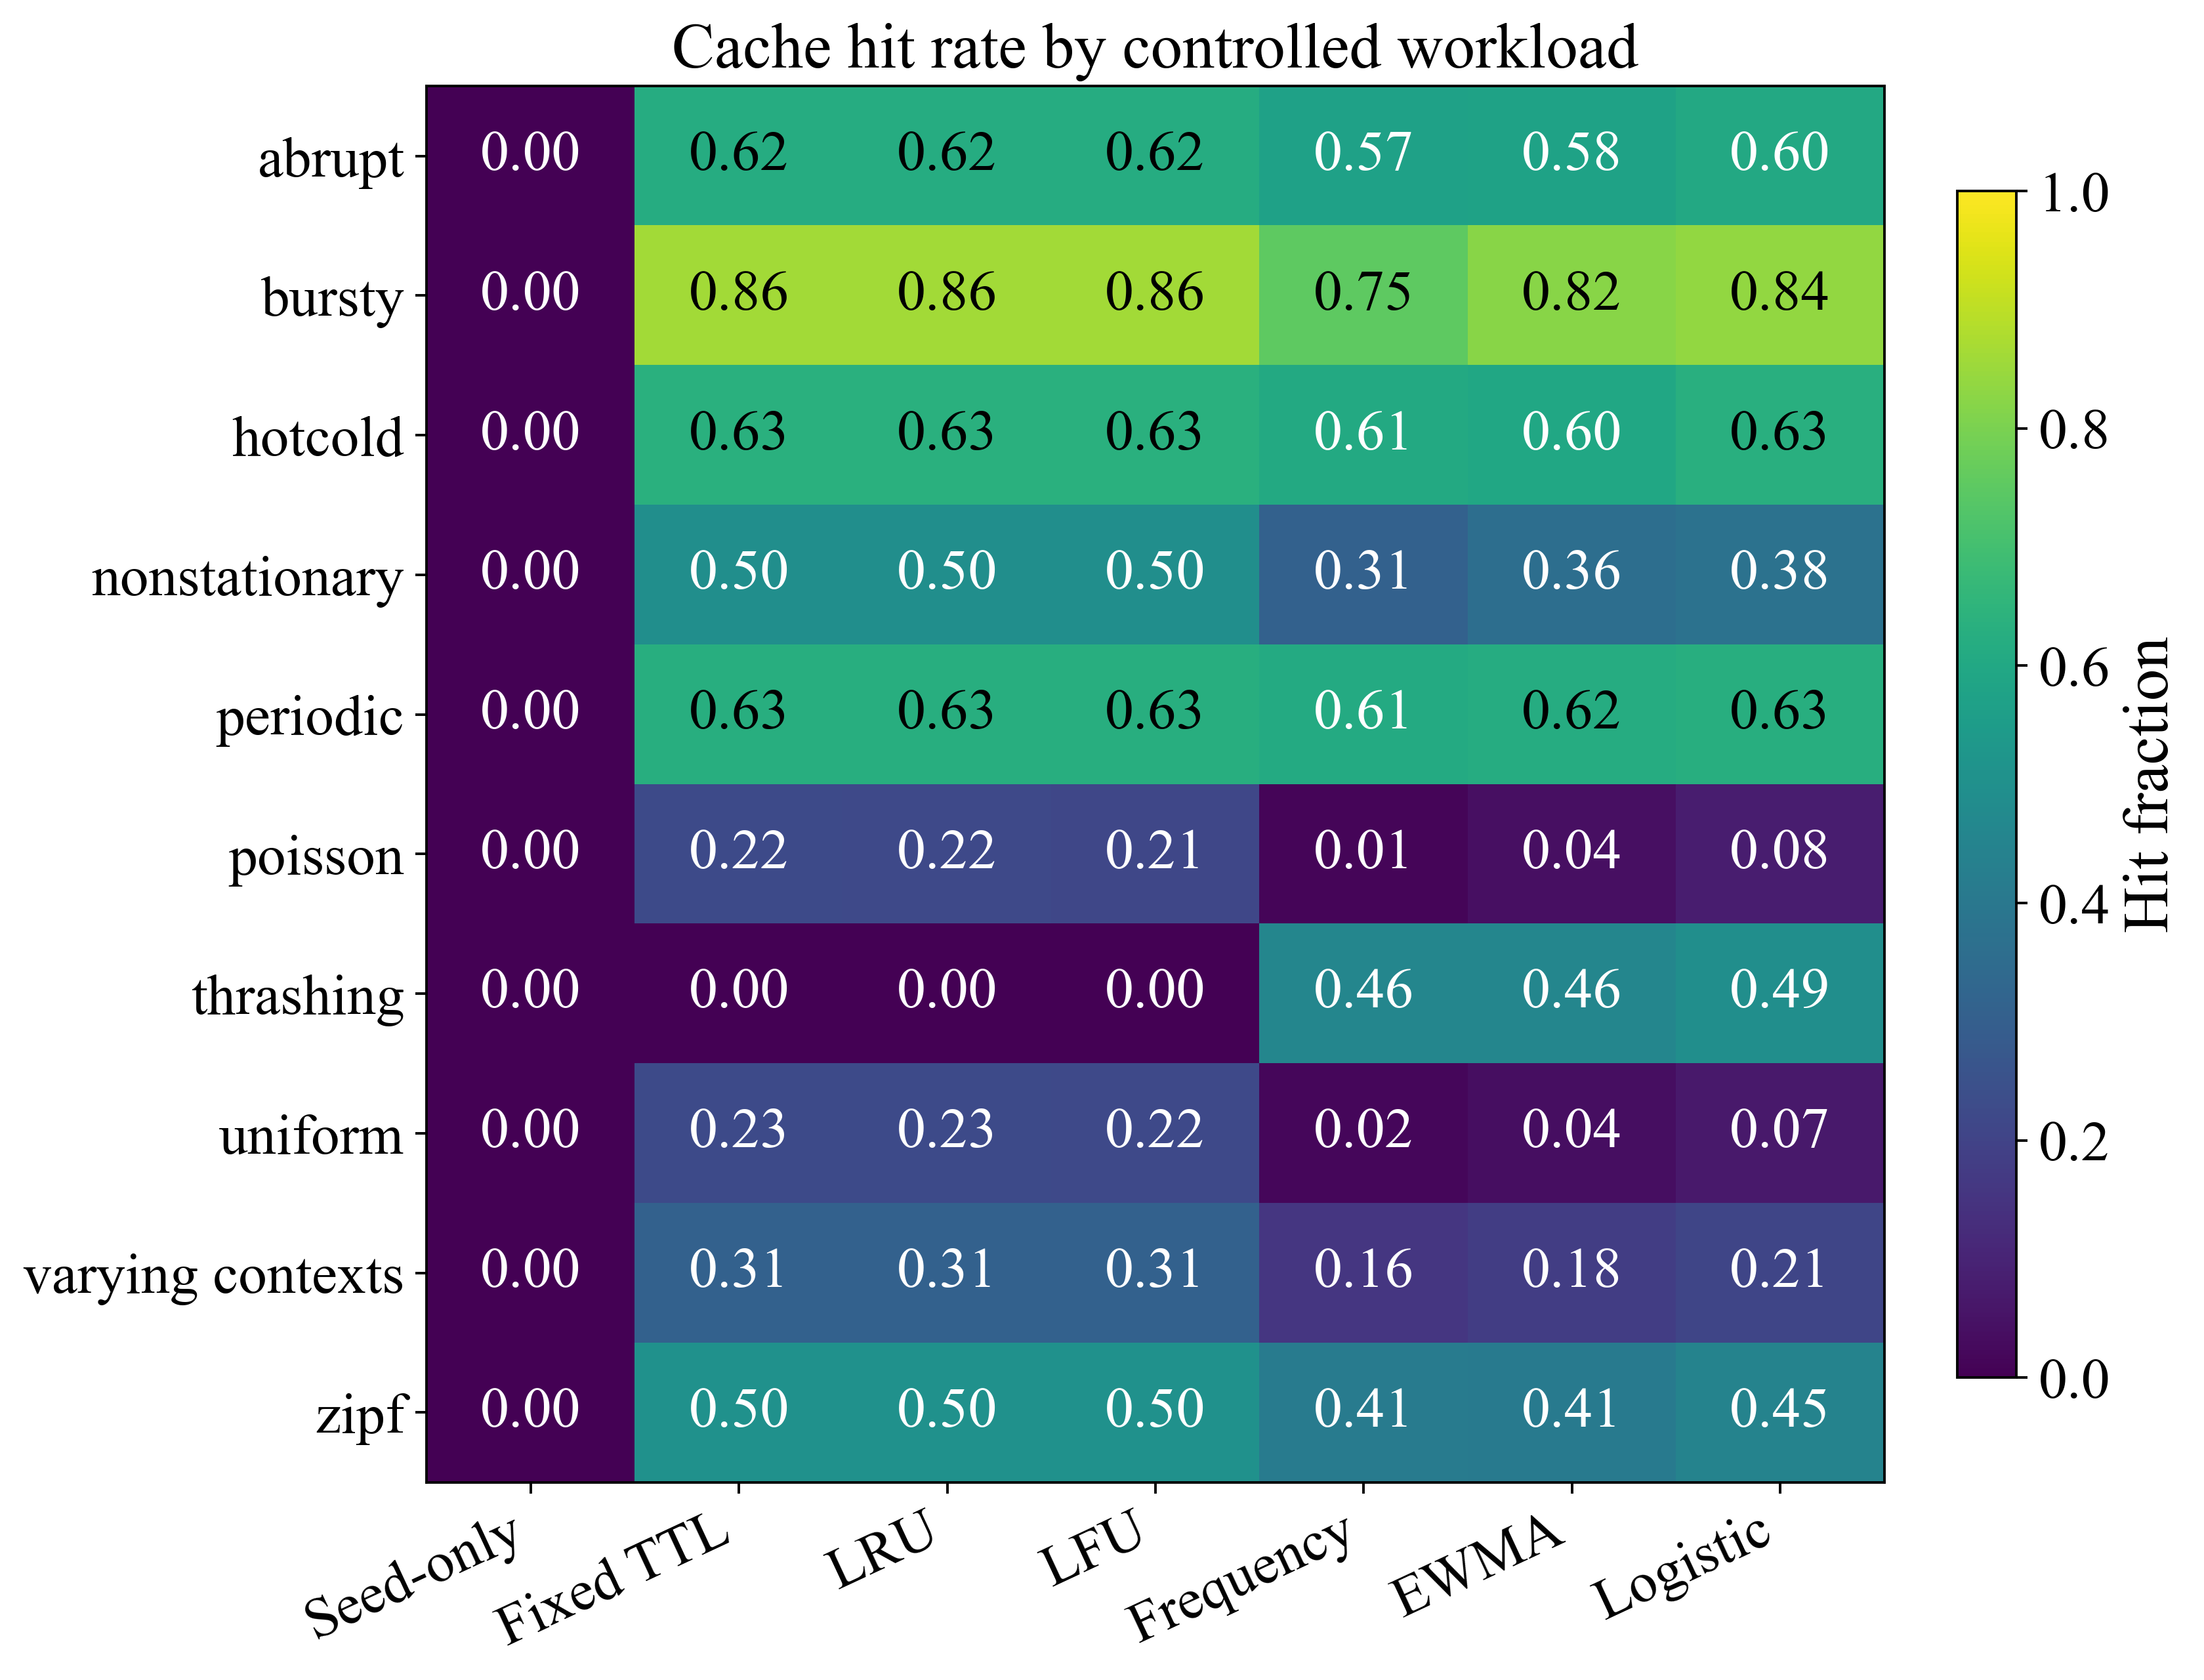

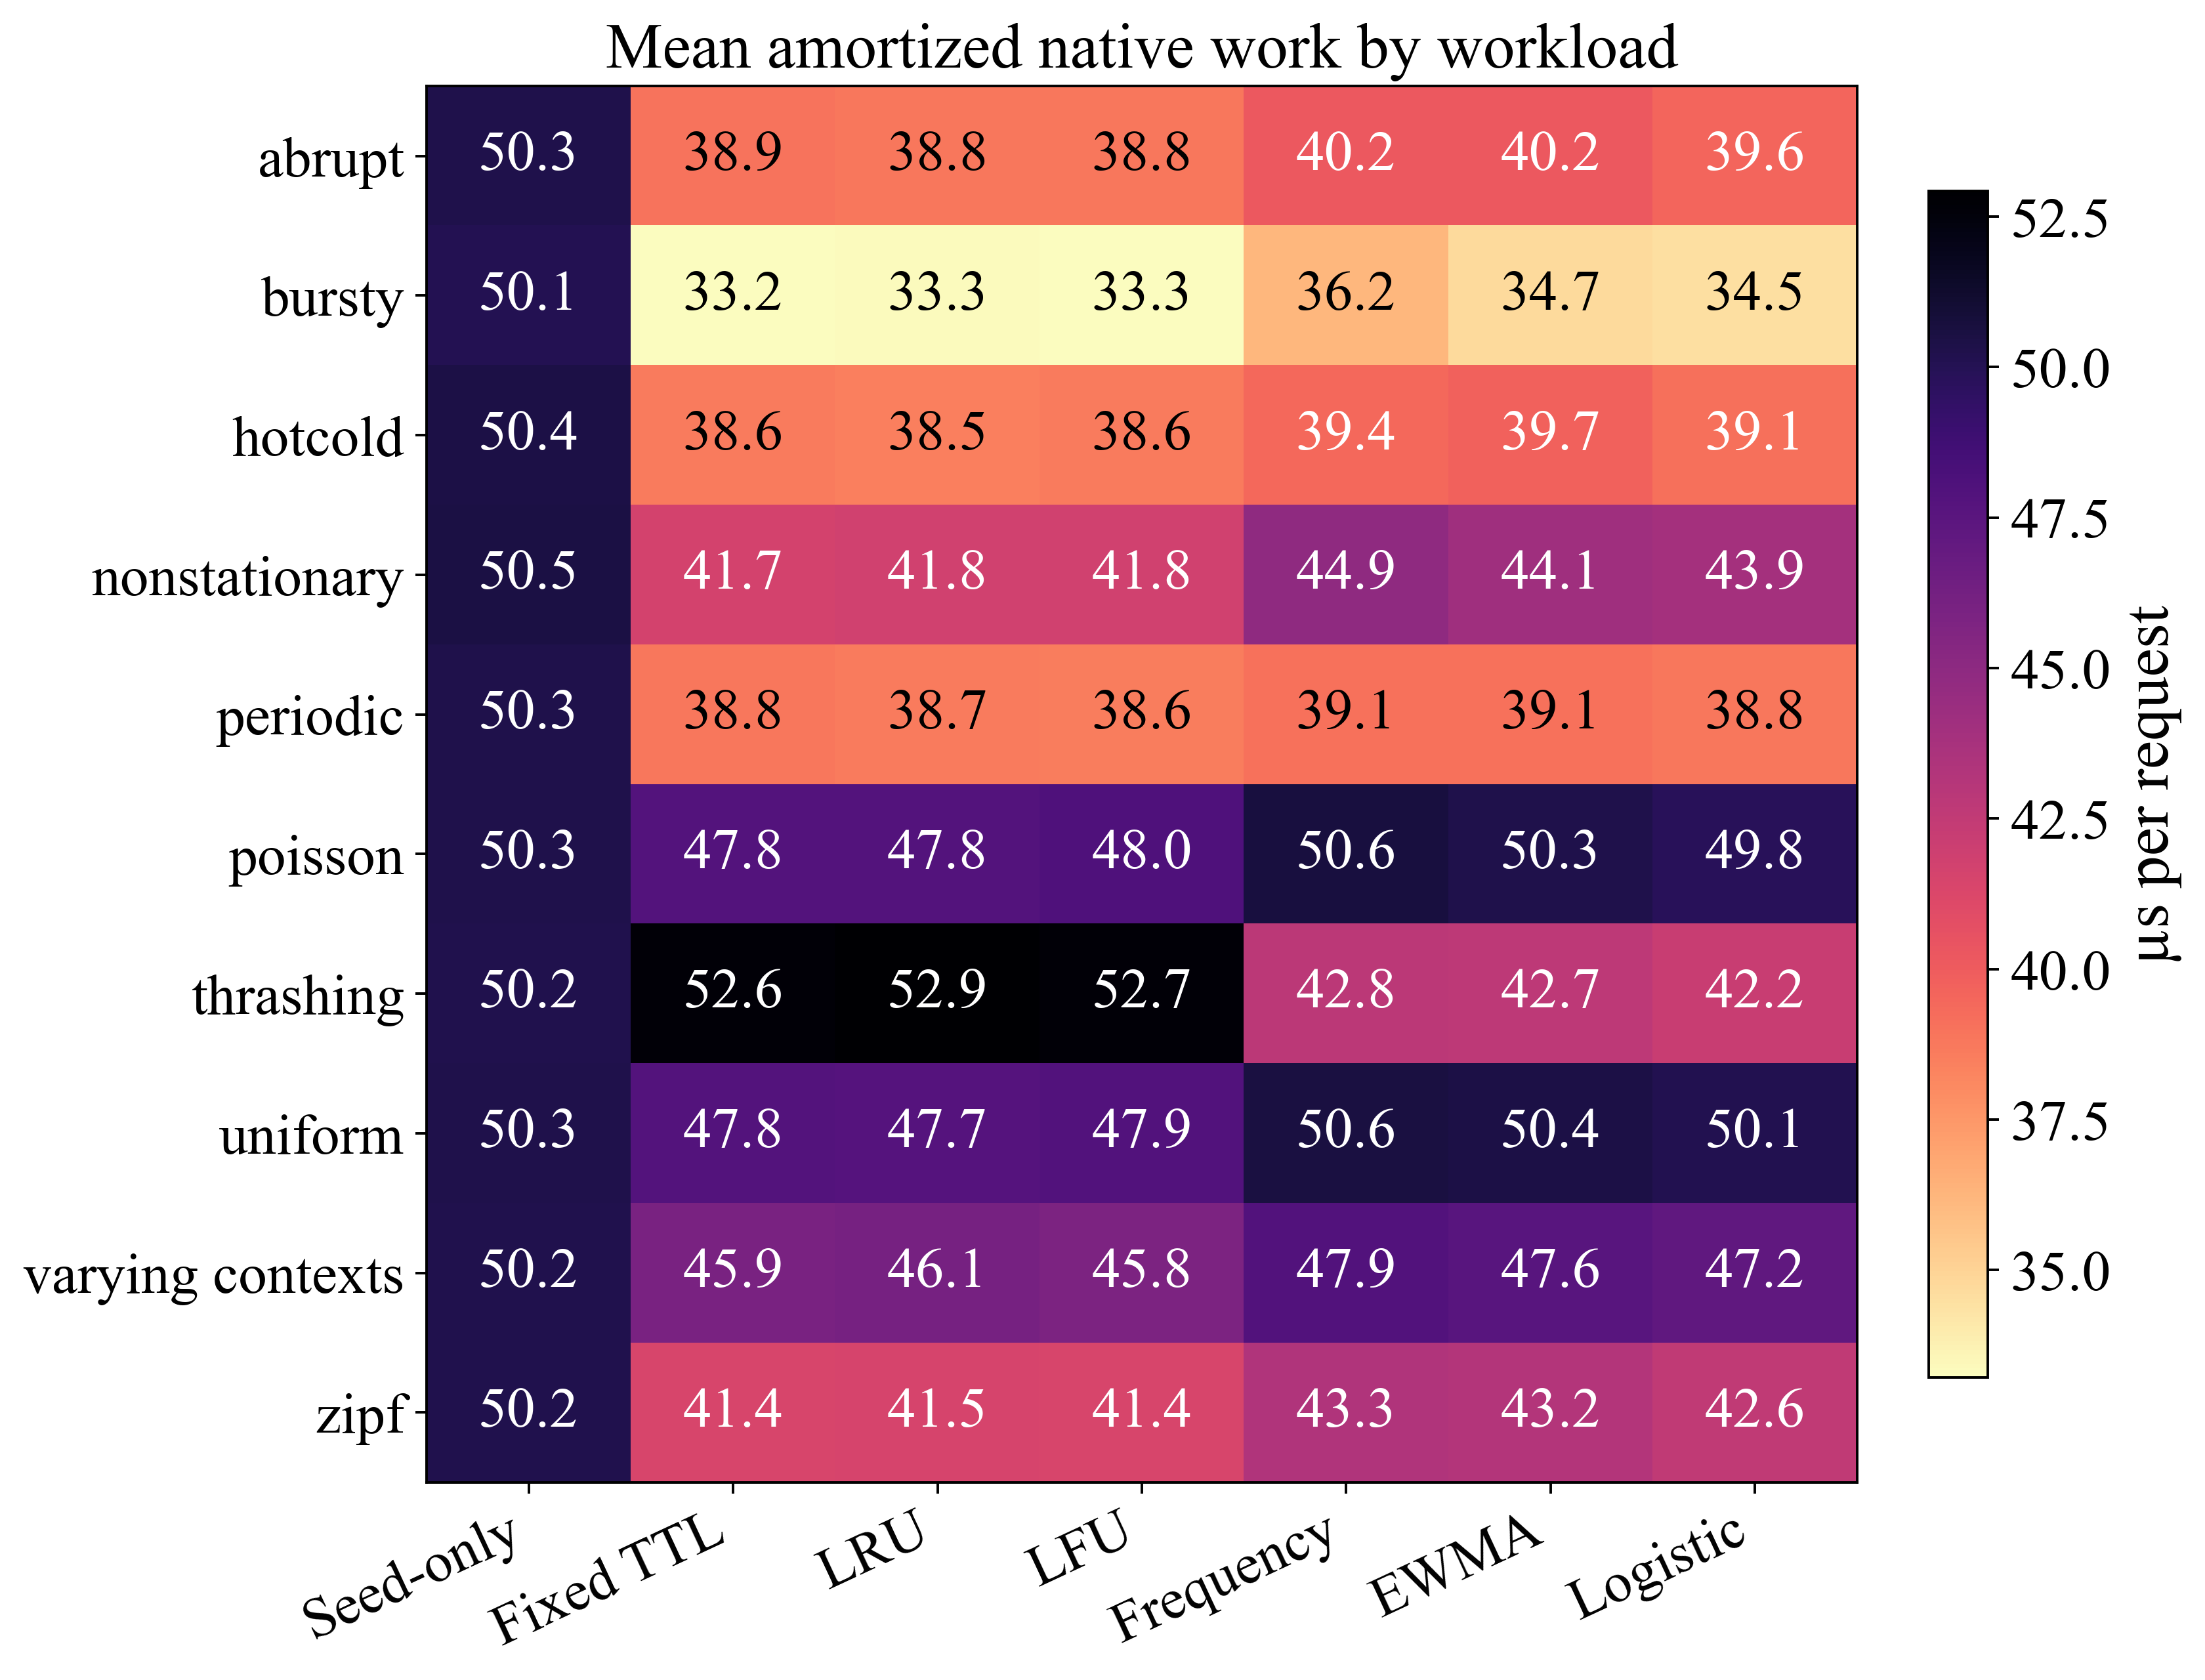

In [13]:
metric_means=native_metrics.groupby("policy").mean(numeric_only=True).reindex(POLICIES)
save_table(metric_means[["hit_rate","miss_rate","reconstructions","service_mean_us","service_p95_us","service_p99_us","amortized_work_us"]],"native_primary_metrics", exclude=['amortized_work_us'])
save_table(metric_means[["response_mean_us","response_p99_us","arrival_throughput_req_s","cycles_mean","prediction_mean_us","idle_maintenance_mean_us"]],"native_response_and_overhead", exclude=["prediction_mean_us", "idle_maintenance_mean_us"])
save_table(metric_means[["sampled_cache_mean_bytes","cache_max_bytes","expanded_key_byte_seconds","locked_arena_bytes","peak_rss_bytes","evictions","zeroizations"]].rename(columns={"cache_max_bytes":"mean_session_peak_cache_bytes","peak_rss_bytes":"mean_session_peak_rss_bytes"}),"native_memory_and_residency")
fig,ax=plt.subplots(figsize=(8.5,5.8),layout="constrained")
v=metric_means.amortized_work_us;sd=native_metrics.groupby("policy").amortized_work_us.std().reindex(POLICIES)
bars=ax.barh([LABELS[p] for p in POLICIES],v,xerr=sd,capsize=4,color=COLORS[0],label="Session mean ± session SD")
for y,(value,err) in enumerate(zip(v,sd)):ax.text(value+err+.6,y,f"{value:.2f}",va="center")
ax.set_xlim(0,(v+sd).max()*1.2);ax.invert_yaxis();ax.set_xlabel("Amortized work per request (µs)");ax.set_title("Native baseline cost including expiry maintenance")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.15),frameon=False)
save_figure(fig,"native_amortized_work",pd.DataFrame({"Policy":POLICIES,"Mean_us":v.to_numpy(),"SD_us":sd.to_numpy()}))
def annotated_matrix(frame,title,scale_label,name,fmt=".2f",vmin=None,vmax=None,cmap="viridis"):
    values=frame.to_numpy();fig,ax=plt.subplots(figsize=(9.5,7.2),layout="constrained")
    im=ax.imshow(values,aspect="auto",cmap=cmap,vmin=vmin,vmax=vmax)
    ax.set_xticks(range(len(frame.columns)),[LABELS.get(p,p) for p in frame.columns],rotation=25,ha="right")
    ax.set_yticks(range(len(frame)),[s.replace("_"," ") for s in frame.index]);ax.set_title(title)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            val=values[i,j];rgba=im.cmap(im.norm(val));lum=.2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
            ax.text(j,i,format(val,fmt).replace("-","−"),ha="center",va="center",color="black" if lum>.55 else "white")
    fig.colorbar(im,ax=ax,label=scale_label,shrink=.85)
    save_figure(fig,name,frame.rename_axis("Workload").reset_index())
hit_matrix=native_metrics.pivot_table(index="workload_id",columns="policy",values="hit_rate").reindex(columns=POLICIES)
work_matrix=native_metrics.pivot_table(index="workload_id",columns="policy",values="amortized_work_us").reindex(columns=POLICIES)
annotated_matrix(hit_matrix,"Cache hit rate by controlled workload","Hit fraction","native_hit_matrix",vmin=0,vmax=1)
annotated_matrix(work_matrix,"Mean amortized native work by workload","µs per request","native_work_matrix",fmt=".1f",cmap="magma_r")

**Cost–residency trade-off.** Fixed TTL had the lowest aggregate measured work among these baselines (42.681 µs/request); Logistic was 42.776 µs/request and Seed-only 50.263 µs/request. Better reuse prediction did not automatically produce a faster controller. Logistic used approximately half the expanded-key byte-seconds of Fixed TTL (6,123.5 versus 12,208.8 per session on average), while the fixed arena and whole-process peak RSS were unchanged. Thus active secret exposure and allocated memory cannot be treated as interchangeable improvements. Frequency/EWMA/Logistic feature-plus-prediction cost was approximately 0.50–0.52 µs per request.

## 03.9. Tail latency, workload effects and paired development differences

Tail values are the mean of within-session p99 estimates, not a pooled p99. Only 1,000 requests exist per session, so tails are noisy. Bootstrap intervals below resample the three paired sessions within each of the ten fixed workload families, retaining the same paired policy contrasts. They are exploratory development intervals on this board, not independent final-test evidence or uncertainty over all real deployments.

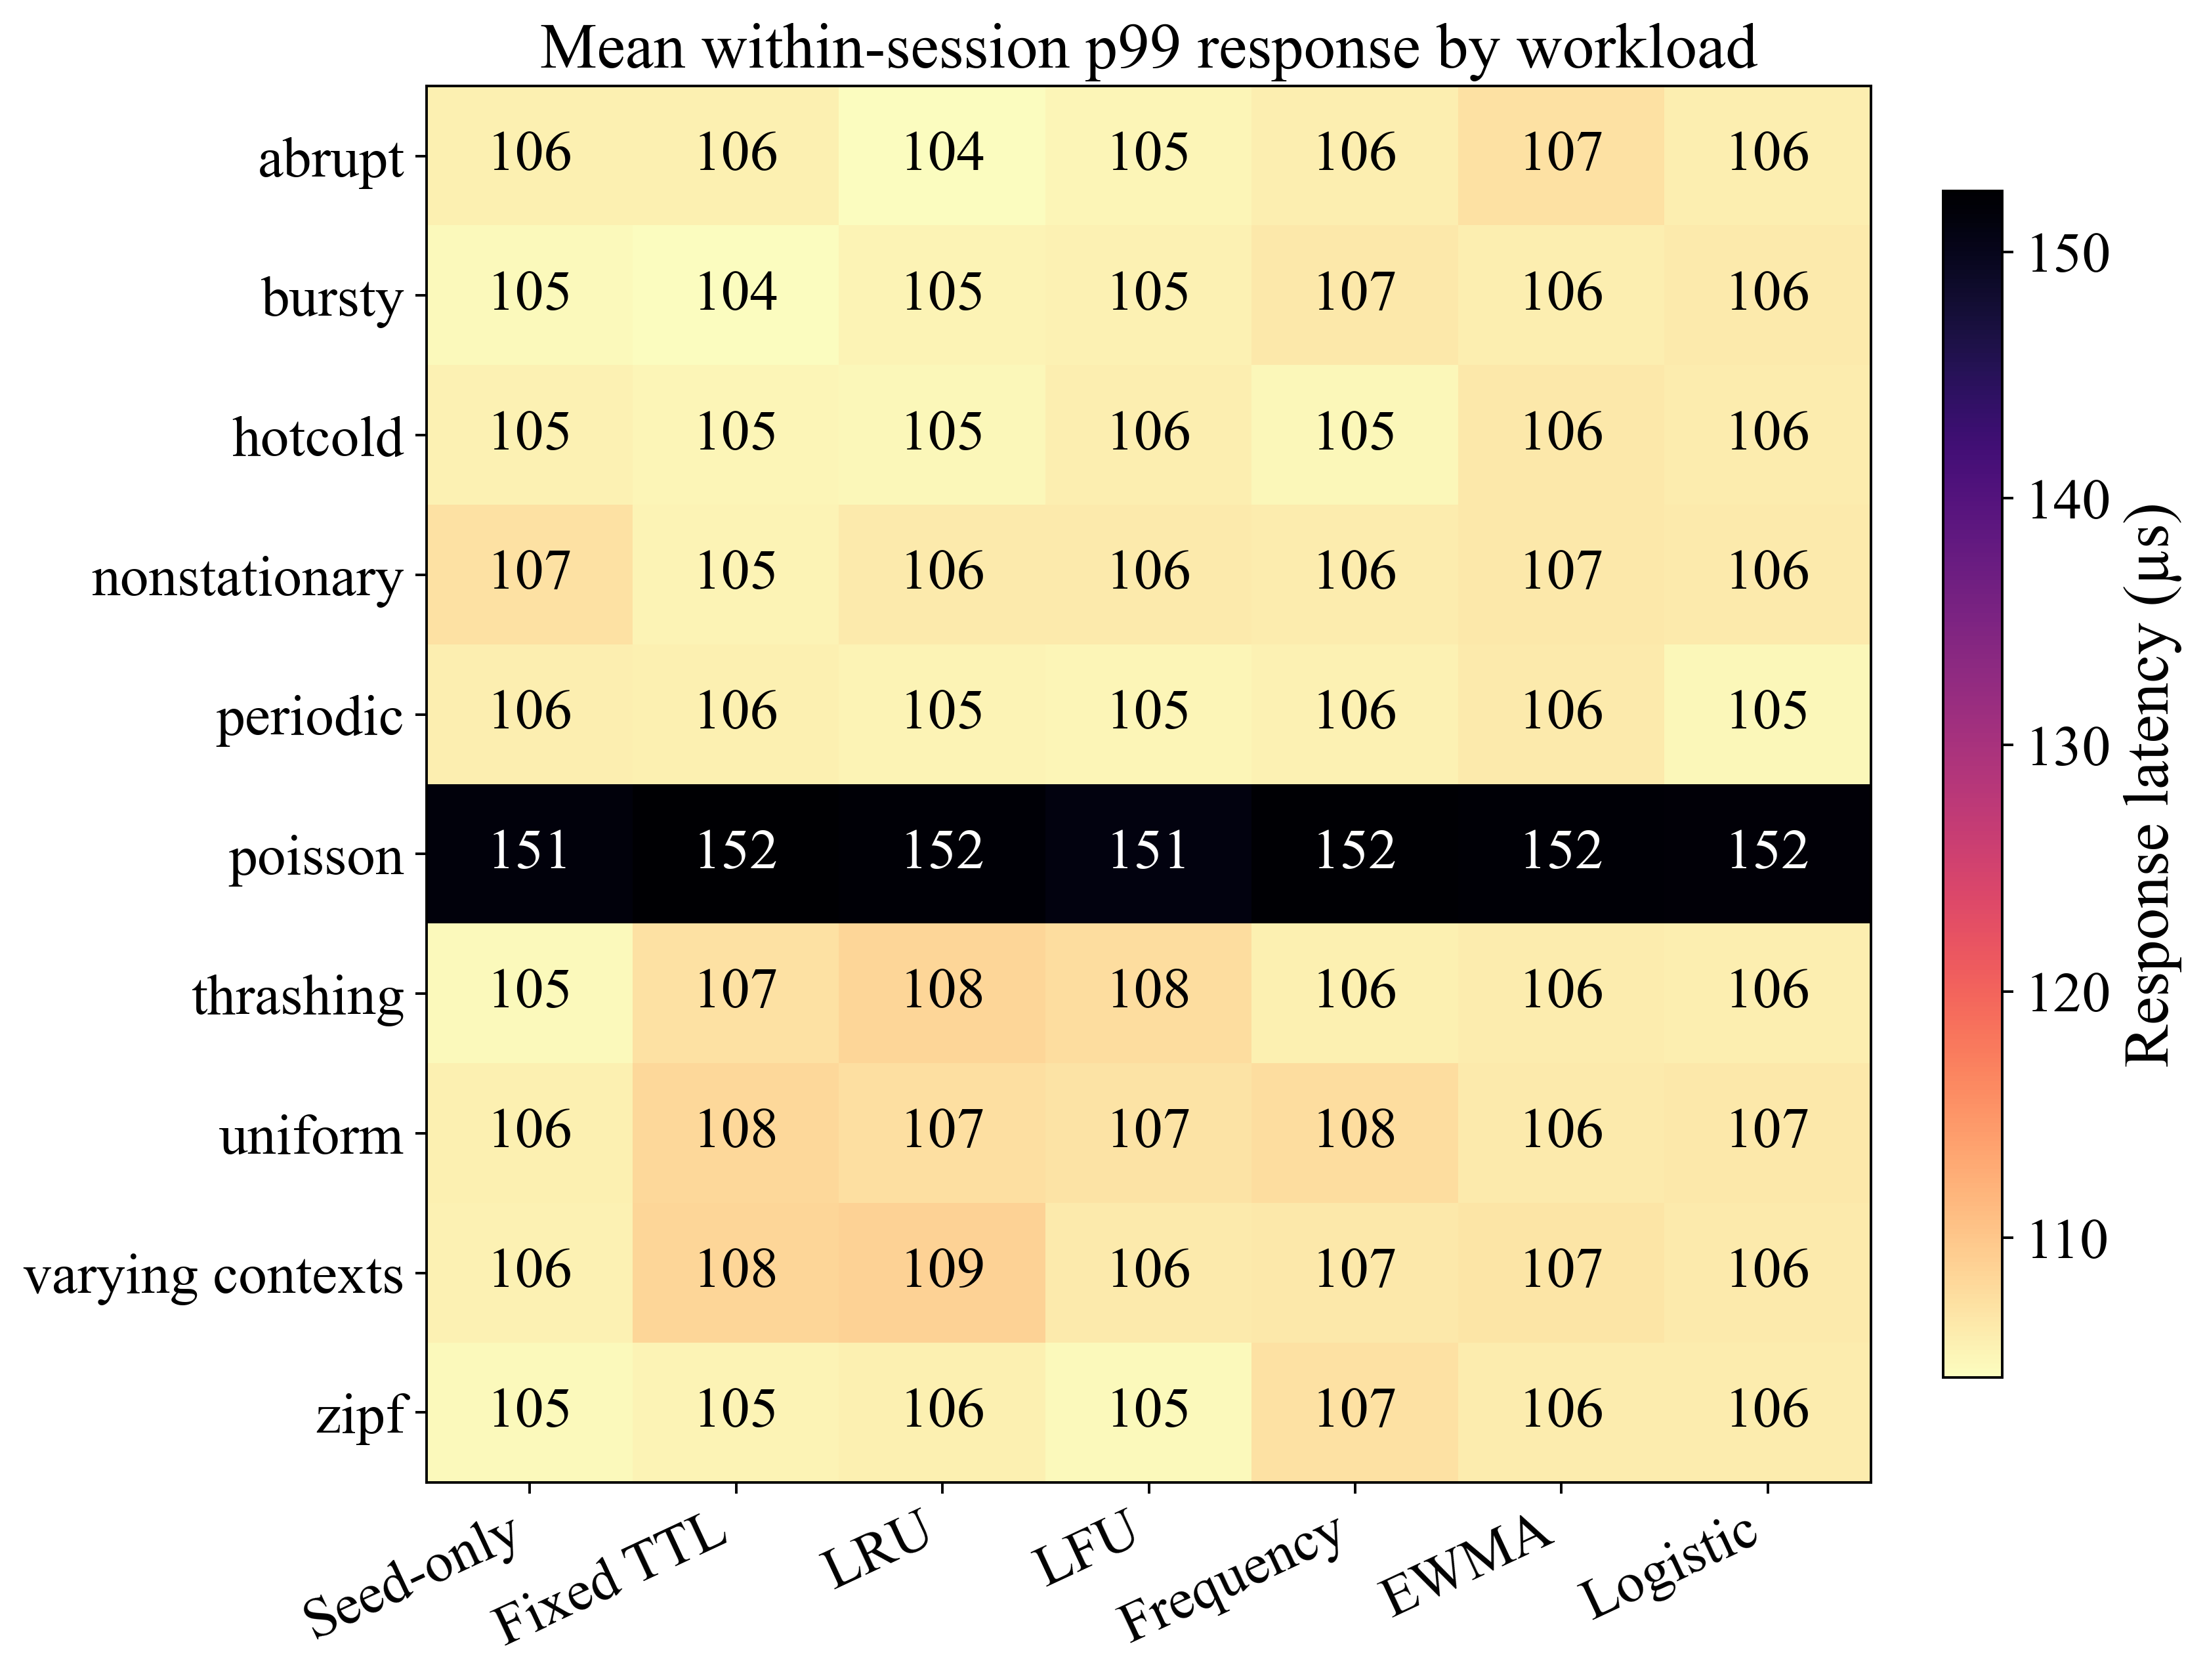

,Mean_saving_vs_seed_only_us,Development_CI_low_us,Development_CI_high_us,Paired_sessions
Policy,,,,
seed_only,0.000000,0.000000,0.000000,30
fixed_ttl,7.581818,7.501932,7.670090,30
lru,7.555491,7.475059,7.639048,30
lfu,7.570286,7.494675,7.640968,30
frequency,6.768749,6.696246,6.840700,30
ewma,7.055064,6.994400,7.116744,30
logistic,7.486921,7.421257,7.555205,30


,session_id,policy,hit_rate,service_p99_us,response_p99_us,prediction_mean_us,amortized_work_us
0,development_poisson_2,frequency,0.014,54.18636,153.43033,0.384723,50.694870
1,development_poisson_2,ewma,0.042,53.70696,153.29283,0.386270,50.195642
2,development_poisson_2,seed_only,0.000,52.87118,153.27749,0.000000,50.286664
3,development_poisson_3,fixed_ttl,0.229,54.59337,152.62376,0.000000,47.570491
4,development_poisson_3,lfu,0.212,54.77800,152.52601,0.000000,48.057889
5,development_poisson_3,frequency,0.009,53.63148,152.42171,0.385379,50.821947
6,development_poisson_1,fixed_ttl,0.220,54.81519,152.40178,0.000000,48.008079
7,development_poisson_2,fixed_ttl,0.222,54.79719,152.37483,0.000000,47.809042
8,development_poisson_2,lru,0.220,54.74229,152.09543,0.000000,47.820298
9,development_poisson_1,lru,0.216,54.66737,152.07136,0.000000,47.902708


,lookup_mean_us,copy_mean_us,clear_mean_us,prediction_mean_us,idle_maintenance_mean_us
policy,,,,,
seed_only,0.034592,0.000000,0.071473,0.000000,0.065959
fixed_ttl,0.057336,0.062173,0.480051,0.000000,0.904830
lru,0.057079,0.062369,0.463362,0.000000,0.922139
lfu,0.057625,0.062582,0.369859,0.000000,1.025494
frequency,0.050123,0.021516,0.075642,0.498751,0.514202
ewma,0.051310,0.024853,0.076797,0.497300,0.573105
logistic,0.053428,0.031871,0.080884,0.516425,0.684179


,Lowest_measured_work_policy,Logistic_minus_best_us
workload_id,,
abrupt,lru,0.768054
bursty,fixed_ttl,1.302420
hotcold,lru,0.632542
nonstationary,fixed_ttl,2.247241
periodic,lfu,0.176555
poisson,fixed_ttl,2.010316
thrashing,logistic,0.000000
uniform,lru,2.417568
varying_contexts,lfu,1.356122


In [14]:
tail_matrix=native_metrics.pivot_table(index="workload_id",columns="policy",values="response_p99_us").reindex(columns=POLICIES)
annotated_matrix(tail_matrix,"Mean within-session p99 response by workload","Response latency (µs)","native_response_p99_matrix",fmt=".0f",cmap="magma_r")
paired=native_metrics.pivot(index=["workload_id","session_id"],columns="policy",values="amortized_work_us").reindex(columns=POLICIES)
savings=paired["seed_only"].to_numpy()[:,None]-paired.to_numpy()
boot_rng=np.random.default_rng(73103);boot=[]
workloads=paired.index.get_level_values("workload_id").to_numpy()
for b in range(2000):
    ids=np.concatenate([boot_rng.choice(np.flatnonzero(workloads==family),size=3,replace=True) for family in sorted(set(workloads))])
    boot.append(savings[ids].mean(axis=0))
boot=np.asarray(boot);low,high=np.quantile(boot,[.025,.975],axis=0)
paired_summary=pd.DataFrame({"Policy":POLICIES,"Mean_saving_vs_seed_only_us":savings.mean(axis=0),"Development_CI_low_us":low,"Development_CI_high_us":high,"Paired_sessions":30}).set_index("Policy")
save_table(paired_summary,"paired_development_work_savings")
worst=native_metrics.nlargest(10,"response_p99_us")[["session_id","policy","hit_rate","service_p99_us","response_p99_us","prediction_mean_us","amortized_work_us"]]
save_table(worst.reset_index(drop=True),"largest_development_tail_delays")
component=native_metrics.groupby("policy")[["lookup_mean_us","copy_mean_us","clear_mean_us","prediction_mean_us","idle_maintenance_mean_us"]].mean().reindex(POLICIES)
save_table(component,"native_measured_components")
regime_summary=work_matrix.idxmin(axis=1).rename("Lowest_measured_work_policy").to_frame()
regime_summary["Work_us"]=work_matrix.min(axis=1)
regime_summary["Logistic_minus_best_us"]=work_matrix.logistic-work_matrix.min(axis=1)
save_table(regime_summary,"regime_winners_development", exclude=["Work_us"])

## 03.10. Transition to modern competitors

The cyclic 17-context workload exceeds a 16-key budget and causes FIFO/LRU/LFU to evict the next useful item: all three achieved zero hits and incurred more work than Seed-only. Logistic achieved a 0.49 hit fraction and 42.185 µs/request in that regime. However, it was slower than the best simple cache in every other family in this comparison. Short-window admission at a fixed 0.5 threshold can reject useful but individually low-probability contexts; retaining stored scores also fails to explicitly account for score ageing or drift. These are measured/inspectable limitations, not proof that a complex proposed method is necessary.

Poisson traffic produced the largest p99 response delays (roughly 152–153 µs in the worst listed sessions), while corresponding p99 service costs stayed near 53–55 µs. Scheduled bursts and OS wake-up/queueing contribute beyond cryptographic service. The approximately 2,008 requests/s aggregate achieved throughput is imposed by these schedules; it does not establish maximum sustainable throughput.

Notebook 04 must test TinyLFU-style admission and stronger tabular predictors with the same TTL/budget and include their full native overhead. It must test calibration and error complementarity before justifying a hybrid controller. Novelty cannot be claimed from seed compression, cache reuse, or a better development Brier score alone. Final evidence still requires fresh held-out sessions, longer runs, rate/budget/TTL sensitivity, ablations and paired statistics after freezing the complete method. There are no measured watts/joules, no production ML-KEM access traces and no cryptographic certification claim.